In [2]:
%autosave 60
%matplotlib notebook
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from nexusformat.nexus import nxload
from pathlib import Path

import datetime
import csv

import os

from matplotlib import dates
from datetime import datetime
from scipy import integrate
from scipy.signal import convolve
from lmfit import minimize, Parameters, Parameter, report_fit 
from lmfit.models import  ConstantModel, VoigtModel, Pearson7Model,GaussianModel, LorentzianModel, LinearModel, ExpressionModel,PolynomialModel,ExponentialModel,StepModel,RectangleModel,LinearModel, QuadraticModel, DampedOscillatorModel
from scipy.interpolate import interp1d


Autosaving every 60 seconds


In [3]:
class Load_file():
    
    def __init__(self,path):
        self.path = path
        nexus = nxload(self.path)
        self._get_attributes_(nexus)
        
    def _get_attributes_(self, nexus):
        #Get attributes from nexus file #
        self.TEY = nexus['entry']['instrument']['fesData']['tey'].nxvalue #TEY #C1
        self.TFY = nexus['entry']['instrument']['fesData']['d90'].nxvalue #C5
        self.Field = nexus['entry']['instrument']['scm']['field_z'].nxvalue
        self.T_sample = nexus['entry']['instrument']['scm']['T_sample'].nxvalue
        self.polarisation = nexus['entry']['instrument']['id']['polarisation'].nxvalue
        self.energy = nexus['entry']['instrument']['fastEnergy']['value'].nxvalue
        self.I0 = nexus['entry']['instrument']['fesData']['i0'].nxvalue #I0 C2
        self.number = str(self.path).split('/')[-1].split('.')[0].split('-')[-1]
        
class XMCD():
    def __init__(self, path_pc, path_nc, xlims = None, ylims = None):
        self.XMCD_edge1 = 576.4
        self.XMCD_edge2 = 578
        
        self.xlims = xlims
        self.ylims = ylims
        
        self.path_pc = path_pc
        self.path_nc = path_nc
        
        self.file_pc = Load_file(self.path_pc)
        self.file_nc = Load_file(self.path_nc)      
        
        if self.file_pc.polarisation != 'pc' or self.file_nc.polarisation != 'nc':
            raise ValueError(f"Polarisation of files does not match (pc {self.file_pc.polarisation}, nc {self.file_pc.polarisation})")
        
        self.energy =  self.file_pc.energy
        self.field = 0.5*(self.file_pc.Field + self.file_nc.Field)
        
    def calculate_XMCD_integrate(self, plot=False):
        """
        Calculate the XMCD by integrating the spectra between the given energy range
        """
        
        self.normalise_XAS()
            
        self.XMCD_spectra = self.file_pc.TEY - self.file_nc.TEY
        
        self.normalise_XMCD()
        
        if plot:
            self.plot_normalise()
            
        peak1, peak1_idx = self.find_nearest(self.energy, self.XMCD_edge1)
        peak2, peak2_idx = self.find_nearest(self.energy, self.XMCD_edge2)
        
        edge1_mask = (self.energy >= peak1 - 0.5) & (self.energy <= peak1 + 0.5)
        edge2_mask = (self.energy >= peak2 - 0.5) & (self.energy <= peak2 + 0.5)
        
        peak_1_I = np.trapz(self.XMCD_spectra[edge1_mask], self.energy[edge1_mask])
        peak_2_I = np.trapz(self.XMCD_spectra[edge2_mask], self.energy[edge2_mask])
        
        if plot:
#             self.n_XMCD_ax.plot(self.energy[edge1_mask],self.XMCD_spectra[edge1_mask], label="Edge 1 region", color = 'm')
#             self.n_XMCD_ax.plot(self.energy[edge2_mask],self.XMCD_spectra[edge2_mask], label="Edge 2 region", color = 'b')
            
#             self.n_XMCD_ax.axvline(x=peak1, color='r', linestyle="--", label = f"{peak1:.2f}")
#             self.n_XMCD_ax.axvline(x=peak2, color='g', linestyle="--", label = f"{peak2:.2f}")
            self.n_XMCD_ax.legend()
        XMCD = peak_1_I - peak_2_I
        return XMCD
    
    def calculate_XMCD_simple(self, plot=False):
        self.normalise_XAS()
            
        self.XMCD_spectra = self.file_pc.TEY - self.file_nc.TEY
        
        self.normalise_XMCD()
        if plot:
            self.plot_normalise()
            
        peak1, peak1_idx = self.find_nearest(self.energy, self.XMCD_edge1)
        peak2, peak2_idx = self.find_nearest(self.energy, self.XMCD_edge2)
        
        
        
        #XMCD = max(self.XMCD_spectra, key=abs) - np.mean(self.XMCD_spectra[:15])
        XMCD = self.XMCD_spectra[peak1_idx] - np.mean(self.XMCD_spectra[:15])
        if plot:
 #           _, idx = self.find_nearest(self.XMCD_spectra, max(self.XMCD_spectra, key=abs))
            self.n_XMCD_ax.axvline(x=self.energy[peak1_idx], color='r', linestyle="--", label = f"{peak1:.2f}", alpha=0.3)
            self.n_XAS_ax.axvline(x=self.energy[peak1_idx], color='r', linestyle="--", label = f"{peak1:.2f}", alpha=0.3)
 #           self.n_XMCD_ax.axvline(x=peak2, color='g', linestyle="--", label = f"{peak2:.2f}")
        return XMCD
                             
    def plot_raw(self):
        """
        Specifically plot the unnormalised XAS to see raw signal
        """
        fig_raw, [r_XAS_ax, r_XMCD_ax] = plt.subplots(1,2,sharey=True)
        
        r_XAS_ax.plot(self.file_pc.energy, self.file_pc.TEY, label = "TEY PC")
        r_XAS_ax.plot(self.file_nc.energy, self.file_nc.TEY, label = "TEY NC")
        r_XAS_ax.set_ylabel("Intensity")
        r_XAS_ax.legend()
        r_XAS_ax.set_xlabel ("Energy (eV)")
        
        r_XMCD_ax.plot(self.energy, (self.file_pc.TEY - self.file_nc.TEY), label = "Raw XMCD")
        r_XMCD_ax.set_xlabel ("Energy (eV)")
        r_XMCD_ax.legend()
        
#         r_XMCD_ax.tight_layout()
        plt.show()
    
    def normalise_XMCD(self):
        """
        Normalise XMCD by dividing by total XAS
        """
        
        self.Averaged_XAS = (self.file_pc.TEY + self.file_nc.TEY)/2
        
        XAS_amplitude = np.max(self.Averaged_XAS) - np.mean(self.Averaged_XAS[:15])
#         print(XAS_amplitude)
        self.XMCD_spectra = self.XMCD_spectra / XAS_amplitude
    
    def normalise_XAS(self):
        """
        Normalise XAS spectra by dividing by I0 and then subtracting the background
        """
        self.file_pc.TEY /= self.file_pc.I0
        self.file_nc.TEY /= self.file_nc.I0
        
        self.file_pc.TEY -= np.mean(self.file_pc.TEY[:10])
        self.file_nc.TEY -= np.mean(self.file_nc.TEY[:10])
        
    def plot_normalise(self):
        
        peak1, peak1_idx = self.find_nearest(self.energy, self.XMCD_edge1)
        XMCD_value = self.XMCD_spectra[peak1_idx] - np.mean(self.XMCD_spectra[:15])
        
        fig_normalise, [self.n_XAS_ax, self.n_XMCD_ax] = plt.subplots(1,2,sharey=False)
        
        self.n_XAS_ax.plot(self.file_pc.energy, self.file_pc.TEY, label = f"TEY {self.file_pc.polarisation} {self.file_pc.number}")
        self.n_XAS_ax.plot(self.file_nc.energy, self.file_nc.TEY, label = f"TEY {self.file_nc.polarisation} {self.file_nc.number}")
        #self.n_XAS_ax.plot((self.file_pc.energy+self.file_nc.energy)/2, self.Averaged_XAS, label = "Avg XAS")
        self.n_XAS_ax.set_ylabel("Intensity")
        self.n_XAS_ax.legend()
        self.n_XAS_ax.set_xlabel ("Energy (eV)")
        if self.ylims is not None:
            self.n_XAS_ax.set_ylim(top=self.ylims[0], bottom=self.ylims[1])
        
        
        self.n_XMCD_ax.plot(self.energy, self.XMCD_spectra, label = f"XMCD {XMCD_value:.2f}")
        self.n_XMCD_ax.set_xlabel ("Energy (eV)")
        self.n_XMCD_ax.legend()
        self.n_XMCD_ax.set_ylim(-1,1)
        
        fig_normalise.suptitle(f'XAS and XMCD for {self.field}T')
        
#         self.n_XMCD_ax.tight_layout()
        plt.show()
    
    def plot_XAS(self):
        
        self.normalise_XAS()
        
        fig_XAS, [pc_ax, nc_ax, avg_ax] = plt.subplots(1,3, sharey=True)
        
        pc_ax.plot(self.file_pc.energy, self.file_pc.TEY, color='r')
        pc_ax.set_title('PC')
        pc_ax.set_ylabel('TEY')
        nc_ax.plot(self.file_nc.energy, self.file_nc.TEY, color='g')
        nc_ax.set_title('NC')
        nc_ax.set_xlabel('Energy (eV)')
        
        avg_ax.plot(((self.file_pc.energy + self.file_nc.energy)*0.5), ((self.file_pc.TEY + self.file_nc.TEY)*0.5), label = 'Avg XAS')
        avg_ax.plot(self.file_pc.energy, self.file_pc.TEY, alpha=0.5, label='PC', color = 'r')
        avg_ax.plot(self.file_nc.energy, self.file_nc.TEY, alpha=0.5, label='NC', color = 'g')
        avg_ax.legend()
        plt.show()
    
    def find_nearest(self, array, value):
        array = np.asarray(array)
        idx = (np.abs(array-value)).argmin()
        
        return array[idx], idx
                             
        

In [4]:
def hysteresis_loop(SN, EN, data_dir=None, plot=False, ylims=[1.6,-0.1]):
    if data_dir is not None:
        print("Directory mode")
        
        files = [(data_dir + f.name) for f in Path(data_dir).iterdir() if f.is_file()]
        files.sort()
    else:
        data_dir = r"/dls/i06-1/data/2026/mm42093-1"
        print("Numbers mode")
        Numbers = np.arange(SN, EN+1, 1)
        start = "/i06-1-"

        files = []

        for number in Numbers:
            files.append(str(data_dir) + start + str(number)+".nxs")
        
    pc_list = []
    nc_list = []
    
    Fields_arr = []
    XMCD_arr = []
    
    for file in files:
        loaded = Load_file(file)
#         print(loaded.number, loaded.polarisation)
        if loaded.polarisation == "pc":
            pc_list.append(loaded)
        elif loaded.polarisation == "nc":
            nc_list.append(loaded)
        else:
            raise ValueError(f"Polarisation")
            
    hyst_fig, hyst_ax = plt.subplots(figsize=(9, 7), layout='constrained')
    
    for i, pc_file in enumerate(pc_list):
        nc_file = nc_list[i] if i < len(nc_list) else None
        
        if nc_file is not None:
            xmcd = XMCD(pc_file.path, nc_file.path, ylims=ylims)
            
#             xmcd_value = xmcd.calculate_XMCD_integrate(plot=plot)
            xmcd_value = xmcd.calculate_XMCD_simple(plot=plot)  
            
            XMCD_arr.append(xmcd_value)
            field = (pc_file.Field + nc_file.Field)/2
            Fields_arr.append(field)
        else:
            raise ValueError(f"No file to pair with {pc_file.path}")
    hyst_ax.set_title(f"Hysteresis loop for {str(data_dir).split('/')[-1]}")
    hyst_ax.set_xlabel("Field (T)")
    hyst_ax.set_ylabel('XMCD/ XAS Amplitude')
    
    half_point = int(len(Fields_arr)/2)
    hyst_ax.plot(Fields_arr[:half_point], XMCD_arr[:half_point],'-o', color='b', label = 'Forward')
    hyst_ax.plot(Fields_arr[half_point:], XMCD_arr[half_point:],'-o', color='r', label = 'Backward')
    hyst_ax.axvline(x=0, alpha = 0.5)
    hyst_ax.axhline(y=0, alpha = 0.5)
    
    
    #hyst_ax.set_xlim(-0.2,0.2)
    #hyst_ax.set_ylim(-0.75,0.75)
    
    hyst_ax.legend()
    
    plt.plot()
    
    

def plot_spectra(path, ax, label = None):
    
    loaded = Load_file(path)                                 
    loaded.TEY /= loaded.I0
    loaded.TEY -= np.mean(loaded.TEY[:15])
                                           
    ax.plot(loaded.energy, loaded.TEY/loaded.I0, label = loaded.number)

# NbSe2 in GI

Numbers mode


<IPython.core.display.Javascript object>


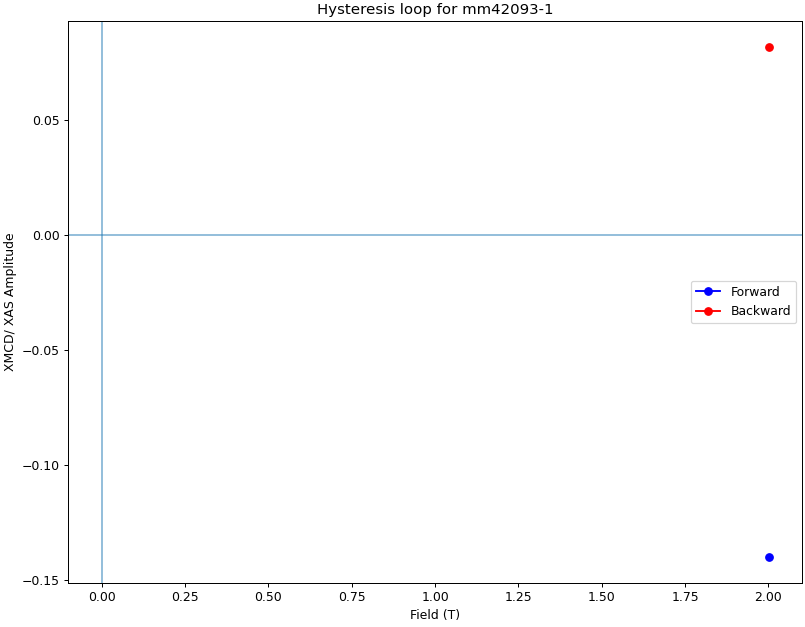

<IPython.core.display.Javascript object>


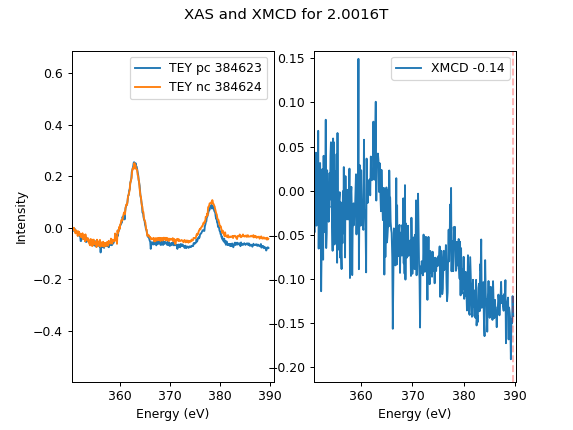

<IPython.core.display.Javascript object>


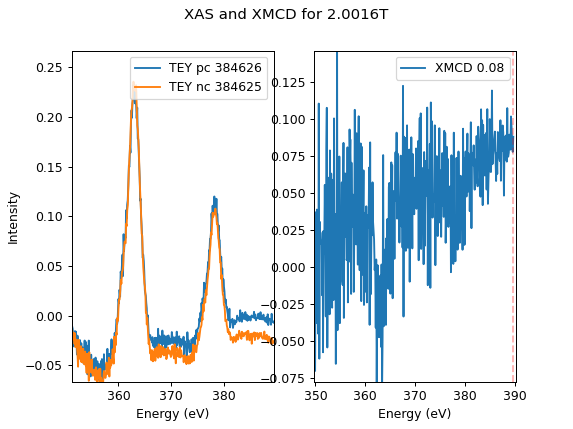

In [70]:
hysteresis_loop(384623,384626,plot=True, ylims=[12,-5])

Numbers mode


<IPython.core.display.Javascript object>


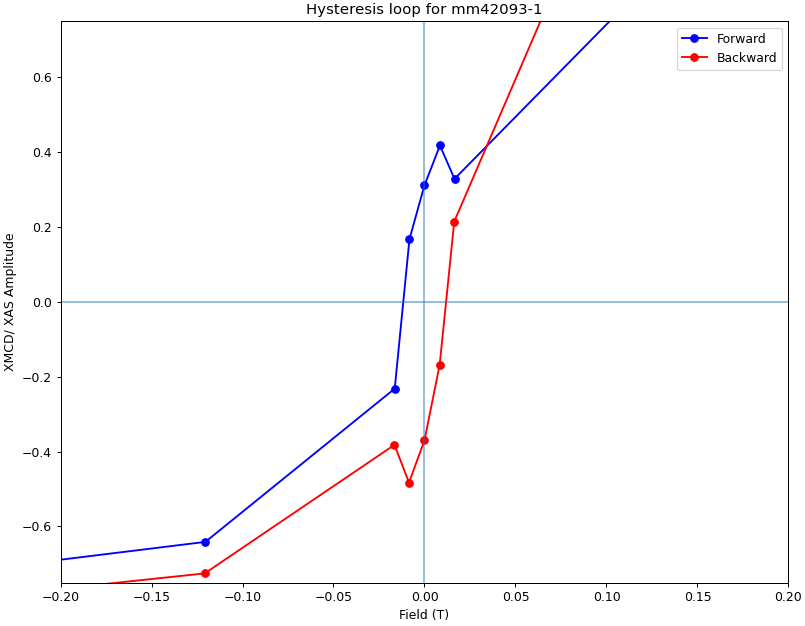

<IPython.core.display.Javascript object>


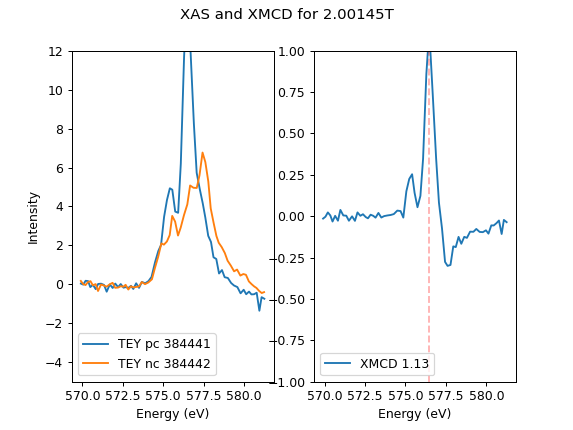

<IPython.core.display.Javascript object>


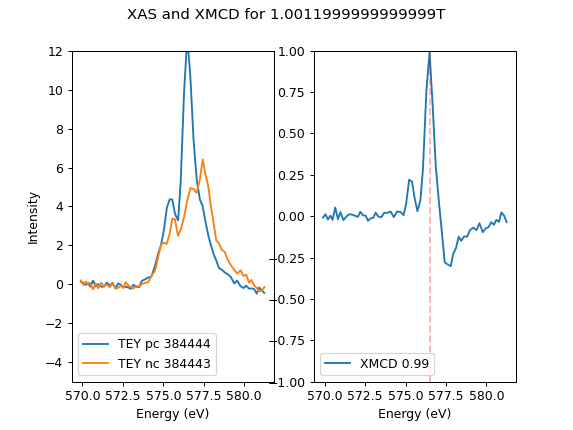

<IPython.core.display.Javascript object>


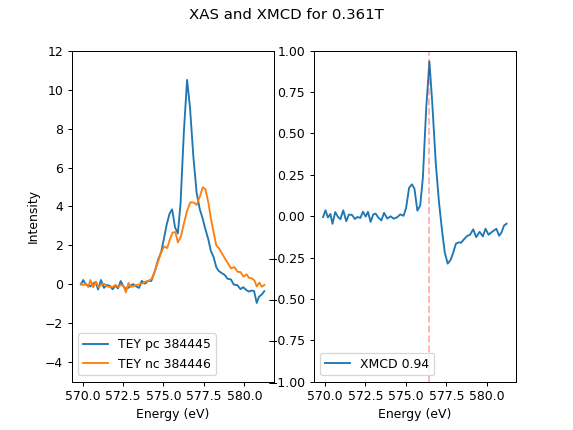

<IPython.core.display.Javascript object>


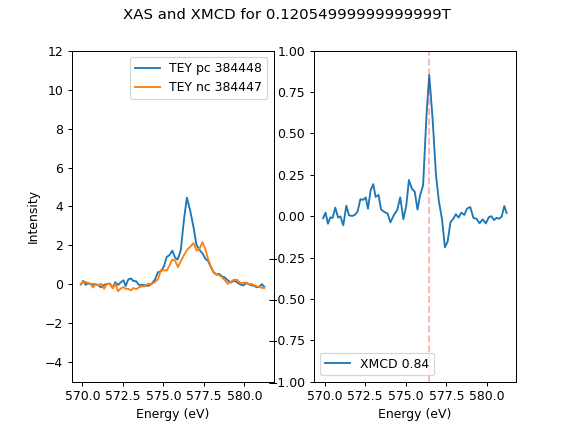

<IPython.core.display.Javascript object>


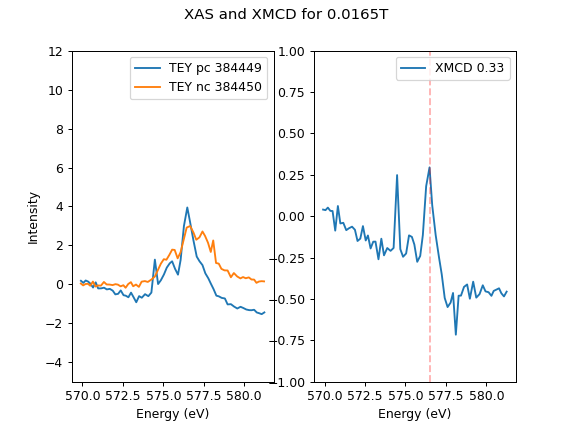

<IPython.core.display.Javascript object>


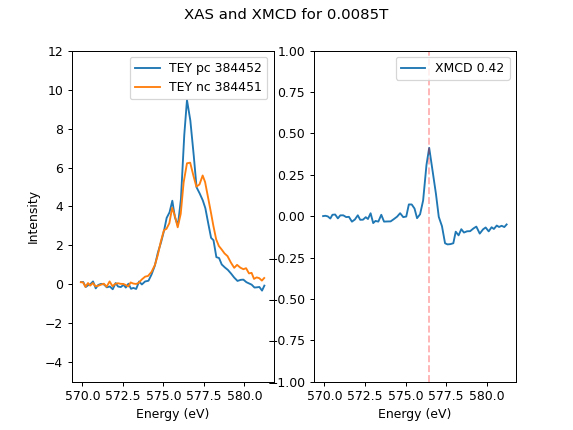

<IPython.core.display.Javascript object>


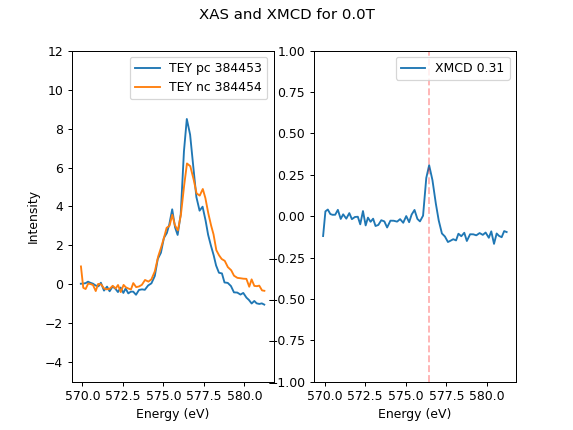

<IPython.core.display.Javascript object>


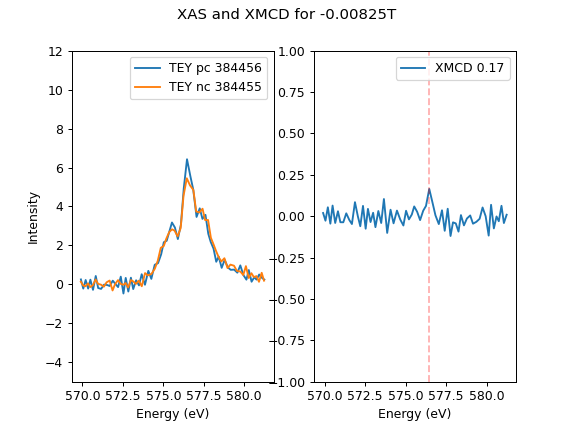

<IPython.core.display.Javascript object>


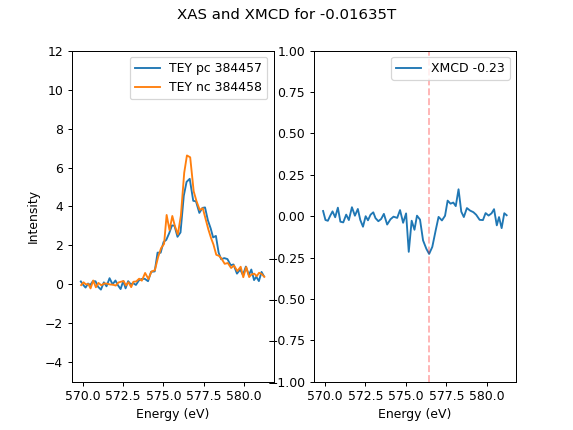

<IPython.core.display.Javascript object>


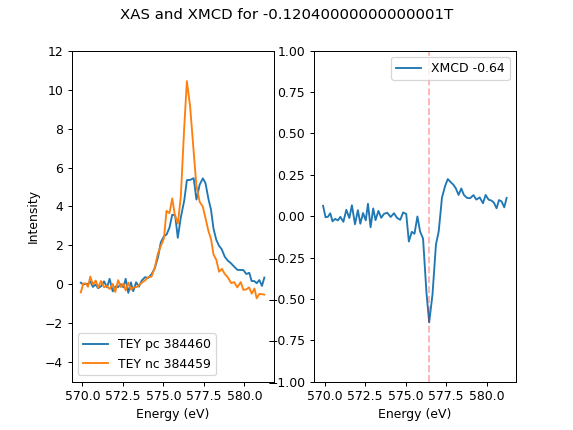

<IPython.core.display.Javascript object>


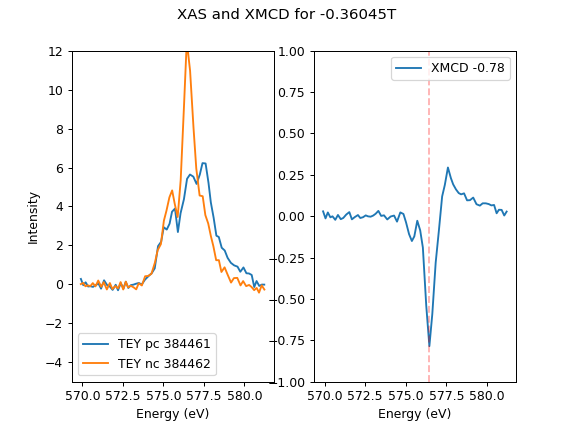

<IPython.core.display.Javascript object>


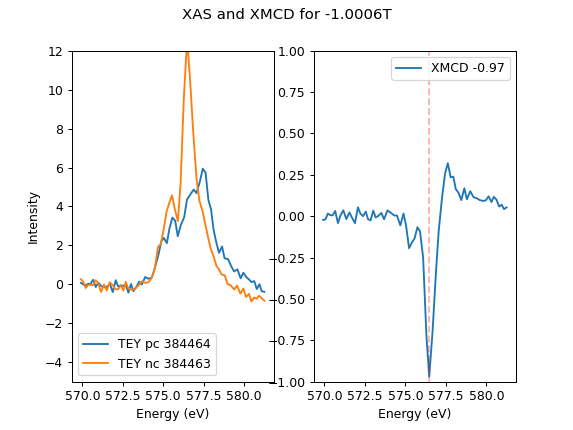

<IPython.core.display.Javascript object>


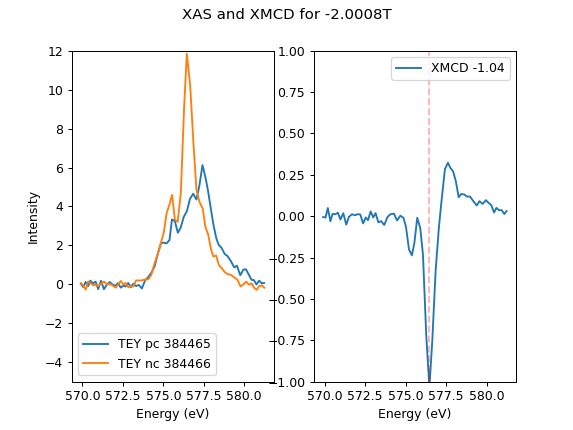

<IPython.core.display.Javascript object>


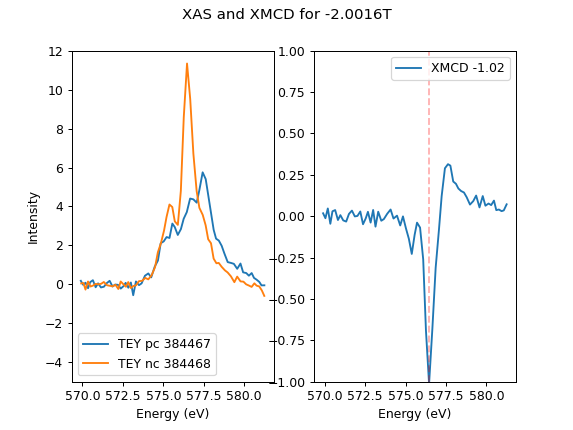

<IPython.core.display.Javascript object>


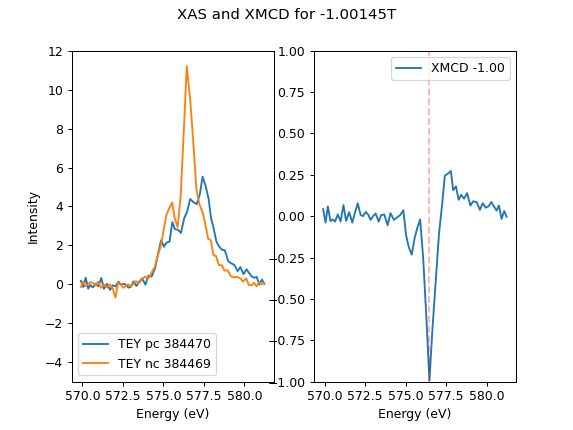

<IPython.core.display.Javascript object>


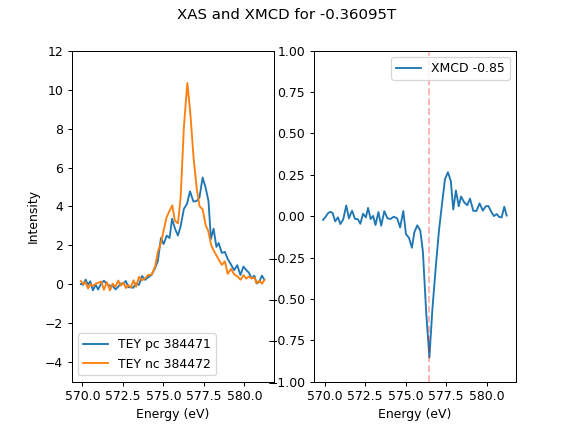

<IPython.core.display.Javascript object>


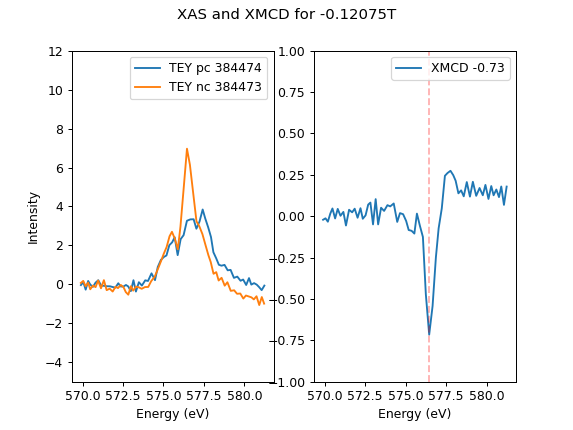

<IPython.core.display.Javascript object>


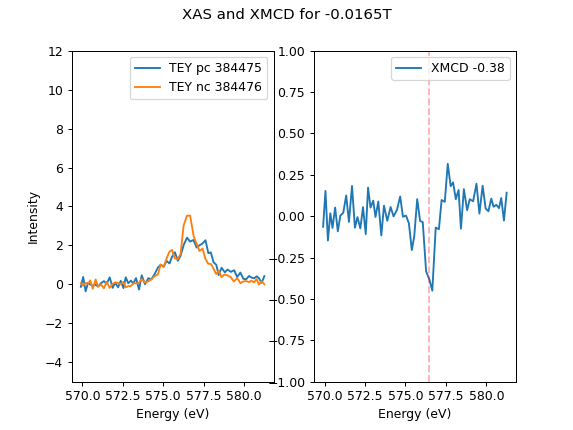

<IPython.core.display.Javascript object>


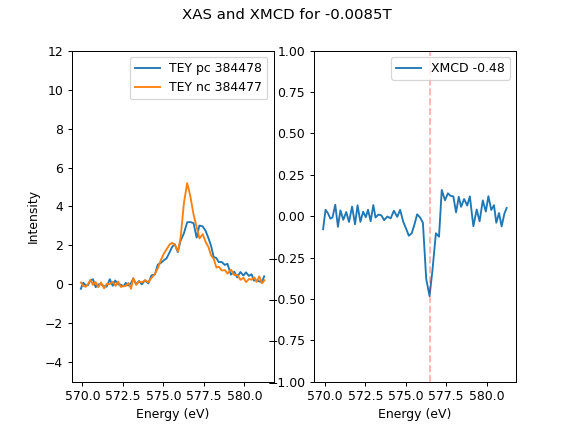

<IPython.core.display.Javascript object>


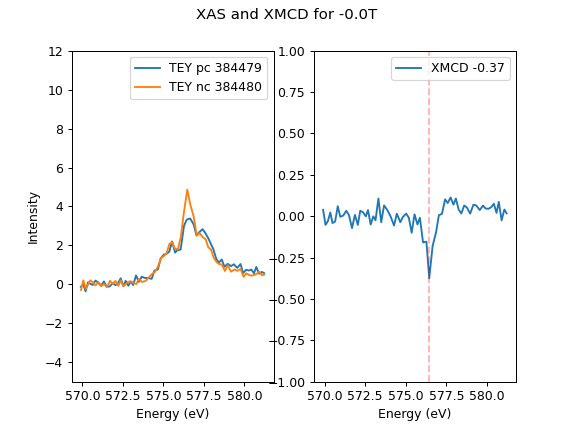

<IPython.core.display.Javascript object>


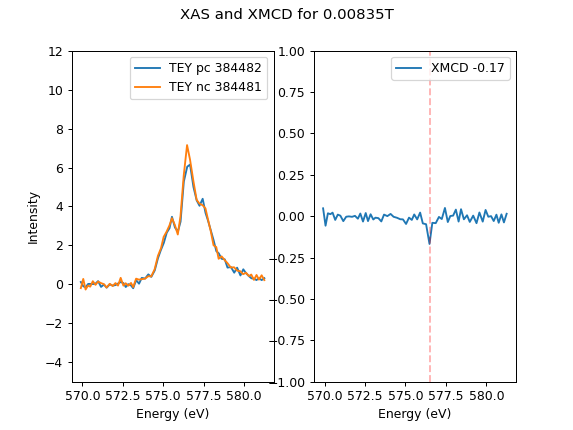

<IPython.core.display.Javascript object>


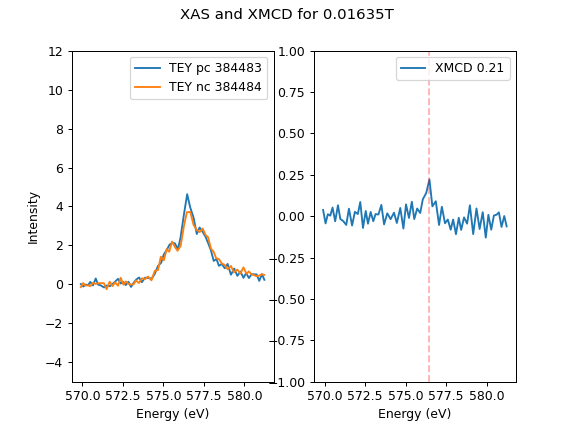

<IPython.core.display.Javascript object>


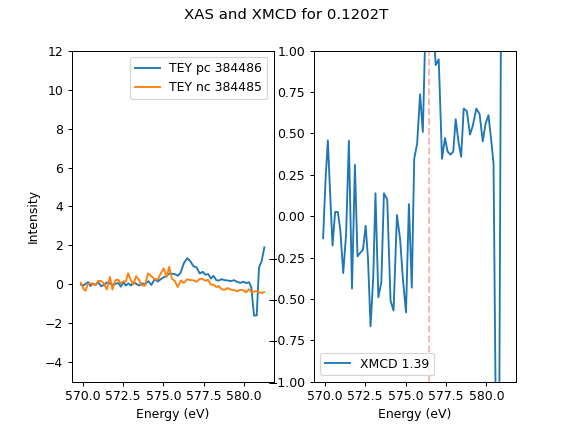

<IPython.core.display.Javascript object>


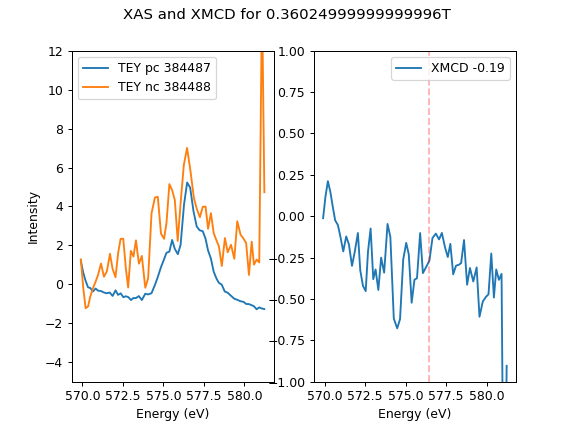

<IPython.core.display.Javascript object>


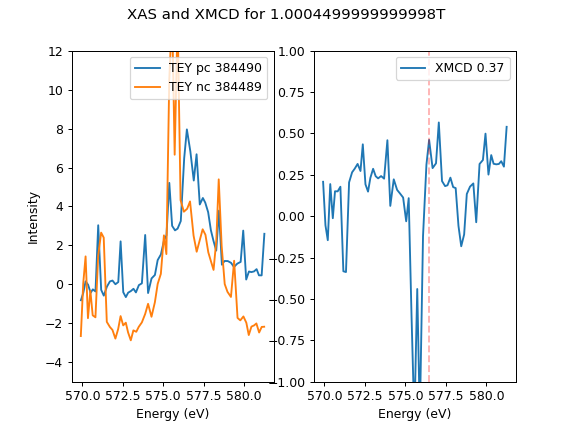

<IPython.core.display.Javascript object>


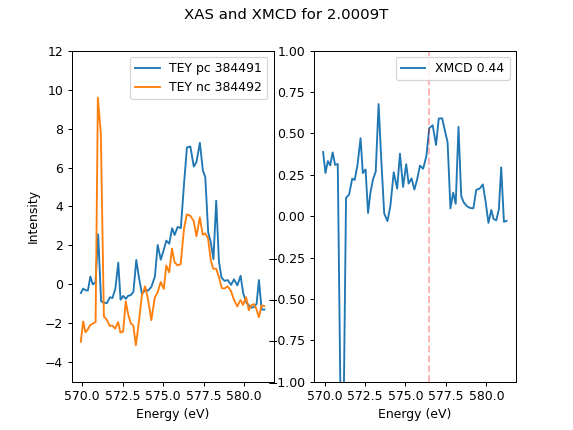

In [62]:
hysteresis_loop(384441,384492,plot=True, ylims=[12,-5])

Numbers mode


<IPython.core.display.Javascript object>


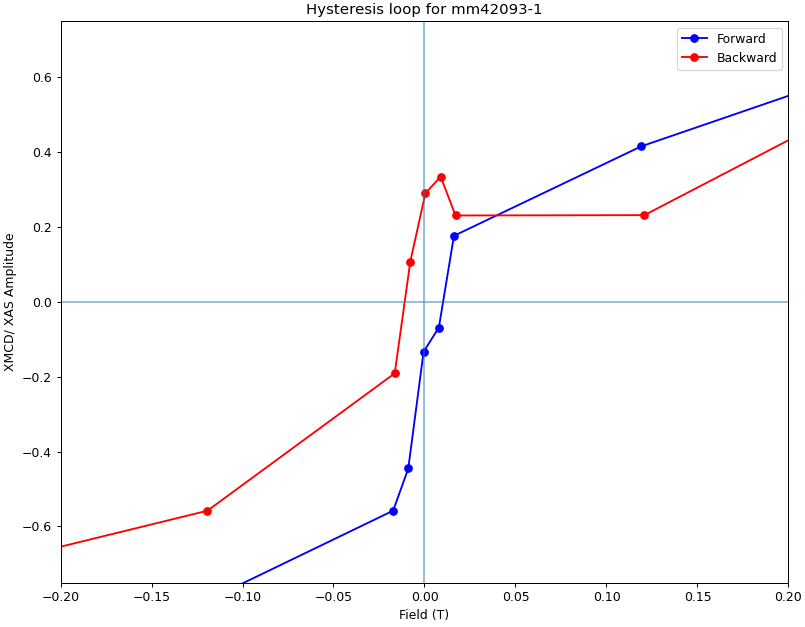

<IPython.core.display.Javascript object>


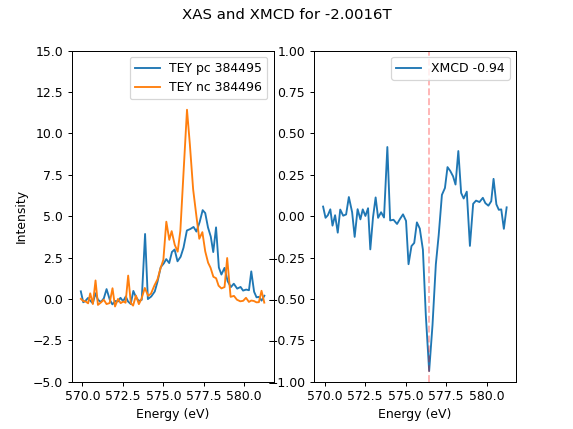

<IPython.core.display.Javascript object>


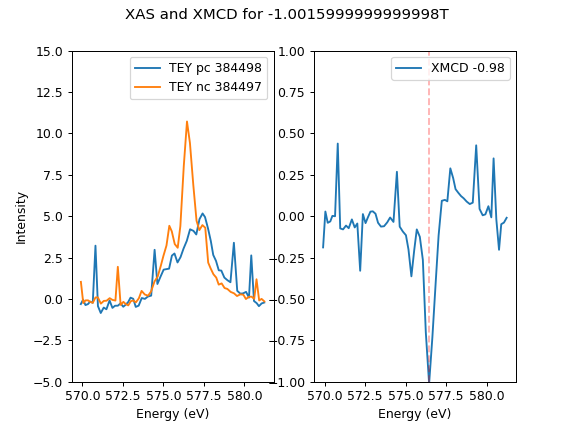

<IPython.core.display.Javascript object>


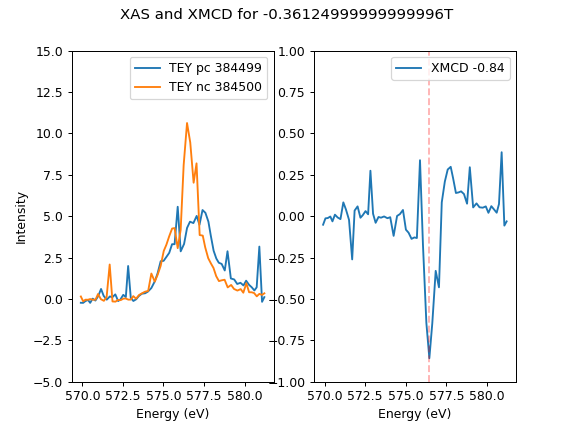

<IPython.core.display.Javascript object>


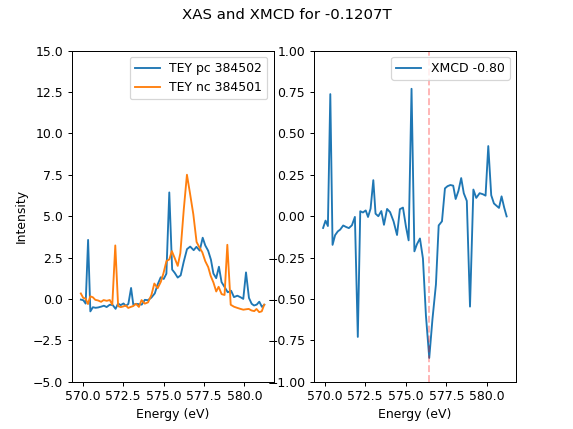

<IPython.core.display.Javascript object>


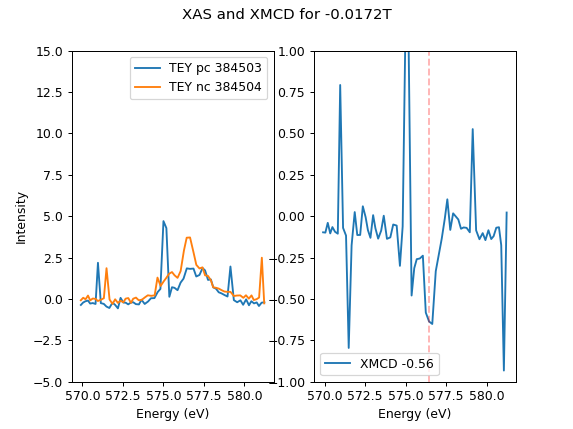

<IPython.core.display.Javascript object>


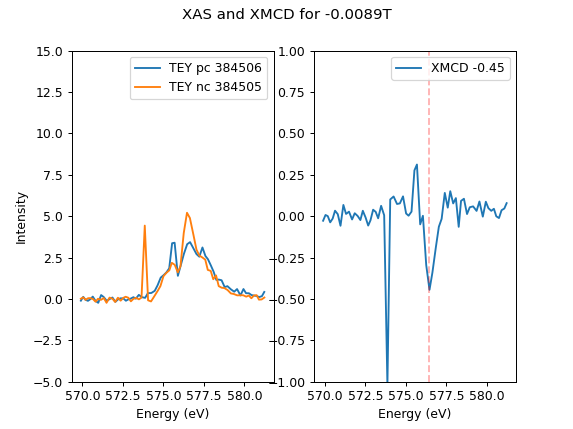

<IPython.core.display.Javascript object>


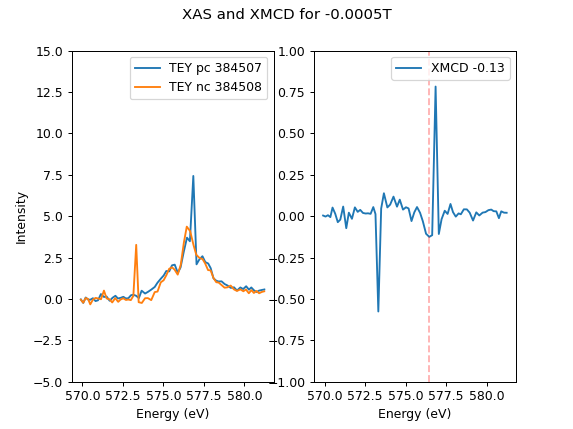

<IPython.core.display.Javascript object>


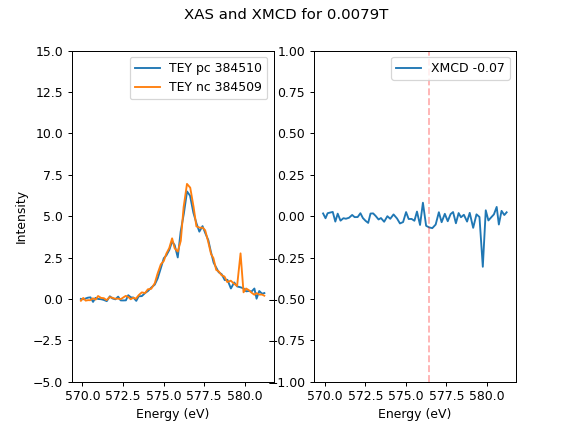

<IPython.core.display.Javascript object>


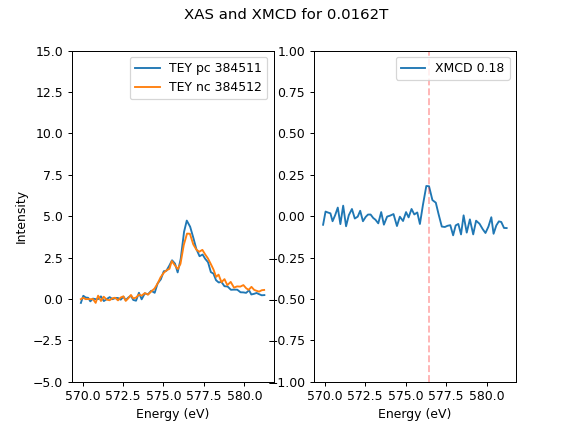

<IPython.core.display.Javascript object>


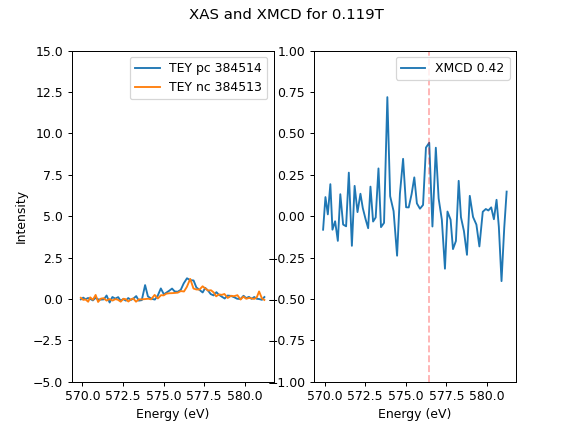

<IPython.core.display.Javascript object>


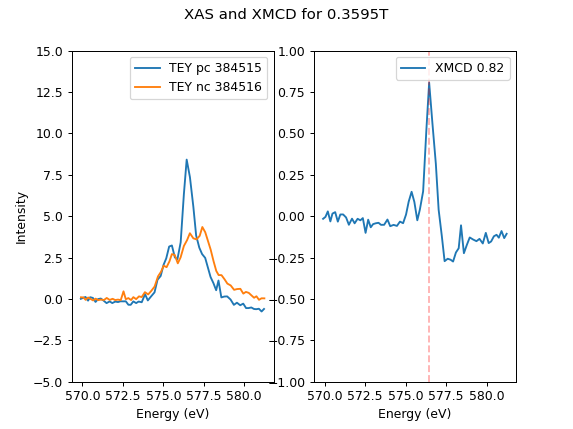

<IPython.core.display.Javascript object>


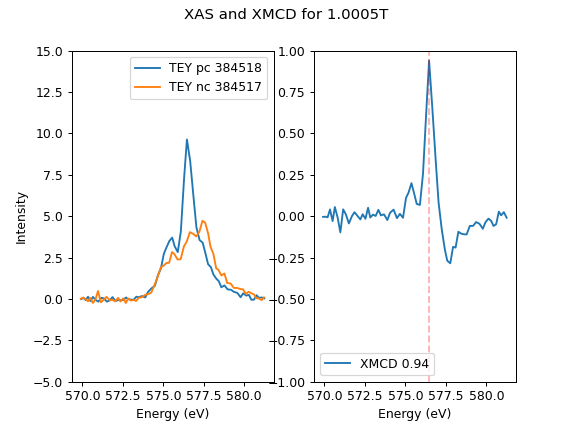

<IPython.core.display.Javascript object>


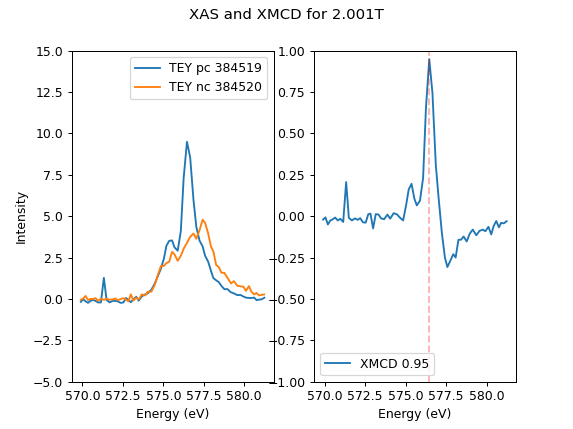

<IPython.core.display.Javascript object>


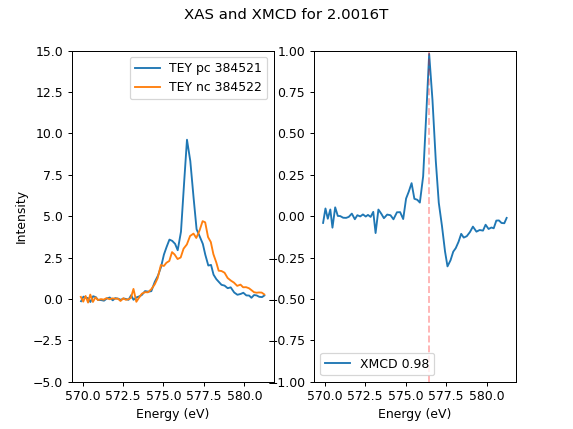

<IPython.core.display.Javascript object>


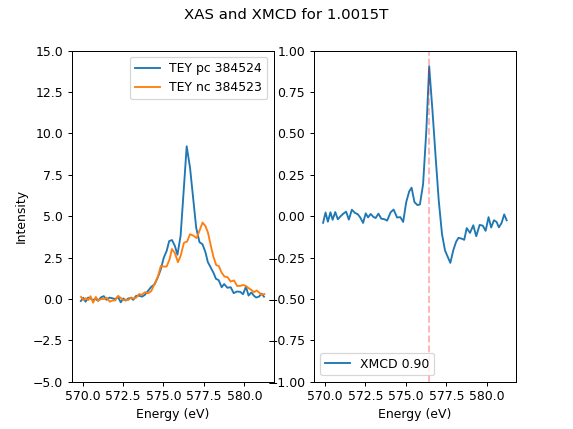

<IPython.core.display.Javascript object>


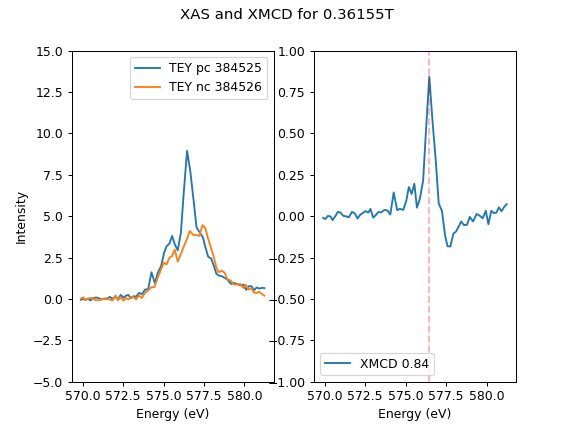

<IPython.core.display.Javascript object>


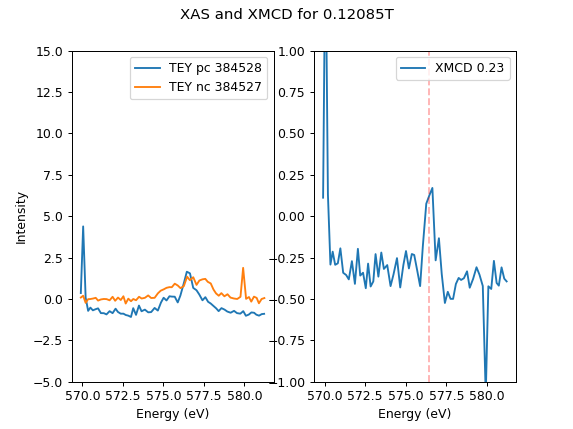

<IPython.core.display.Javascript object>


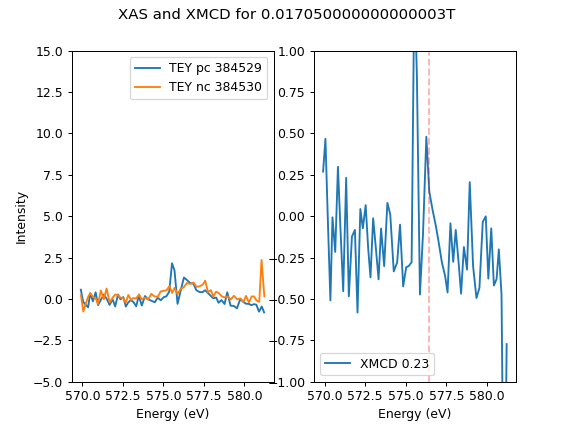

<IPython.core.display.Javascript object>


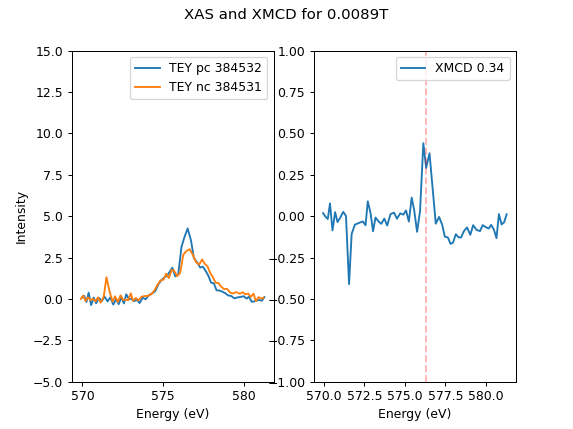

<IPython.core.display.Javascript object>


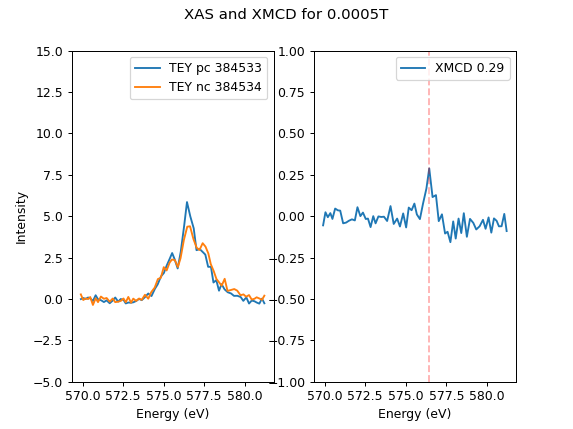

<IPython.core.display.Javascript object>


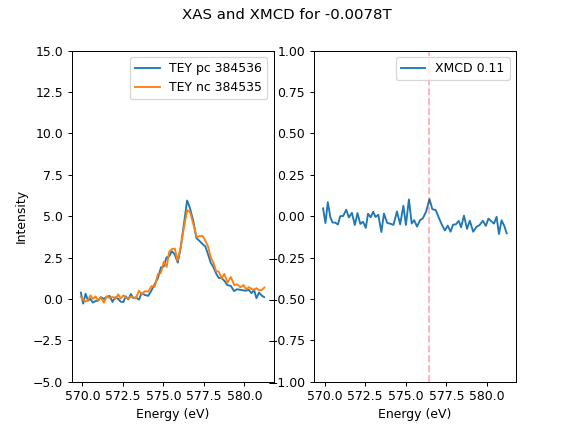

<IPython.core.display.Javascript object>


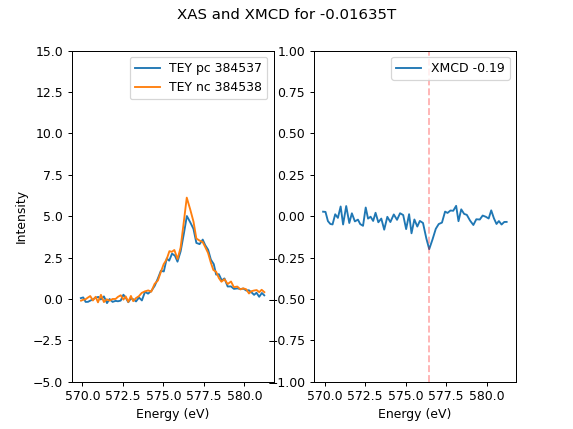

<IPython.core.display.Javascript object>


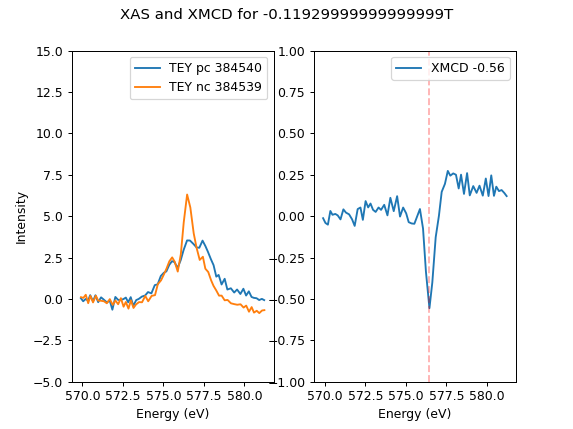

<IPython.core.display.Javascript object>


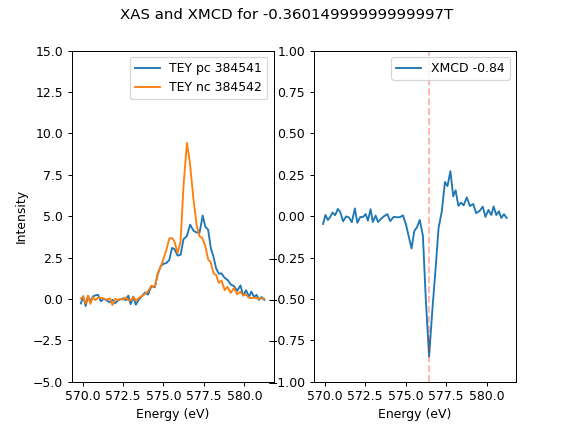

<IPython.core.display.Javascript object>


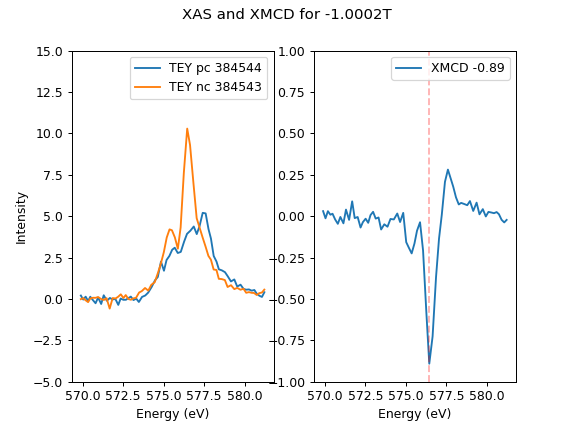

<IPython.core.display.Javascript object>


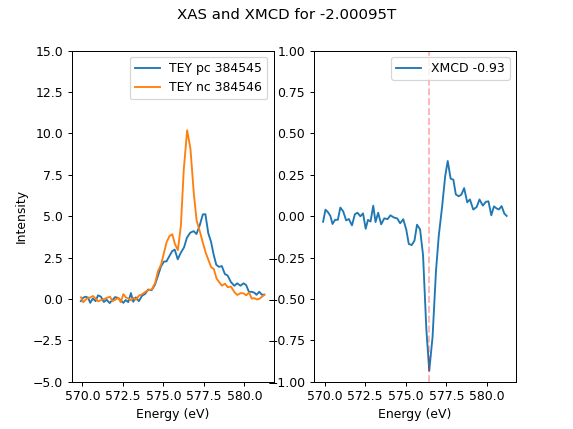

In [63]:
hysteresis_loop(384495,384546,plot=True, ylims=[15,-5])

Numbers mode


<IPython.core.display.Javascript object>


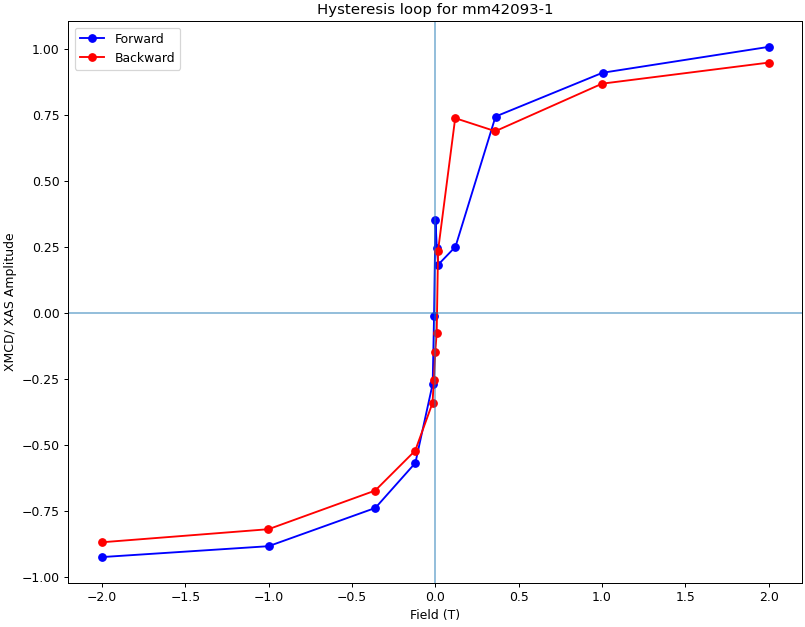

<IPython.core.display.Javascript object>


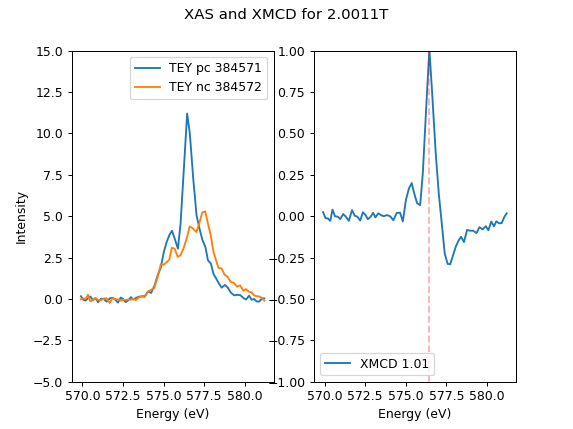

<IPython.core.display.Javascript object>


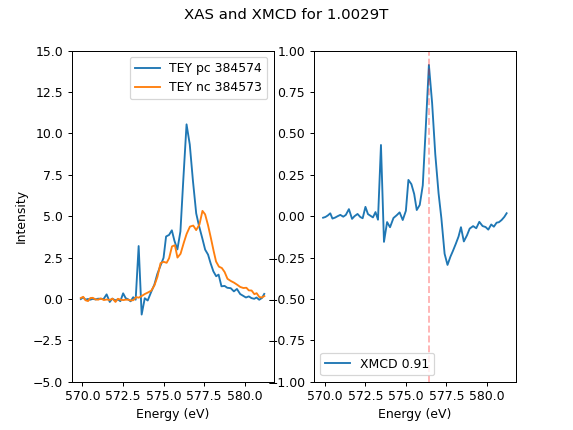

<IPython.core.display.Javascript object>


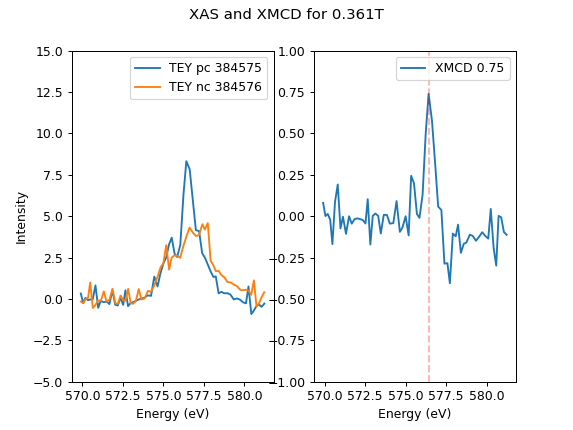

<IPython.core.display.Javascript object>


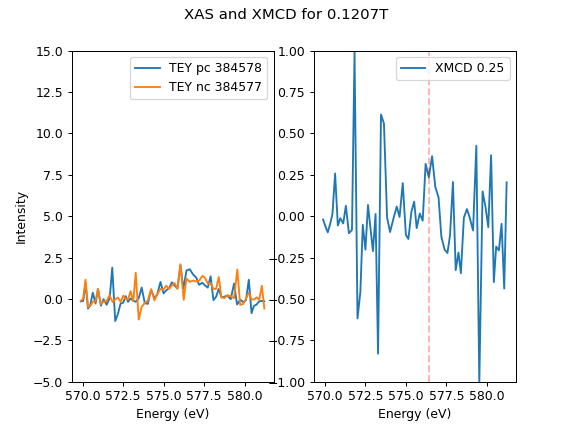

<IPython.core.display.Javascript object>


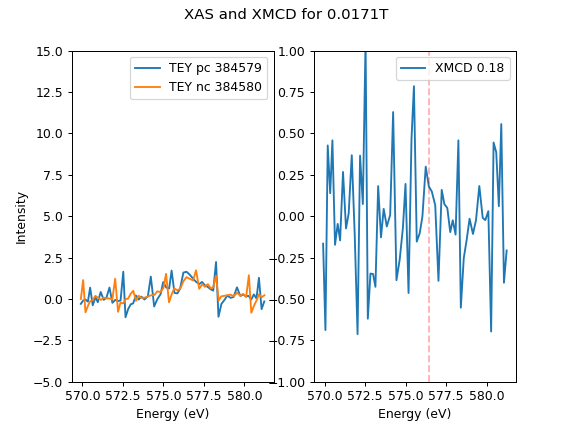

<IPython.core.display.Javascript object>


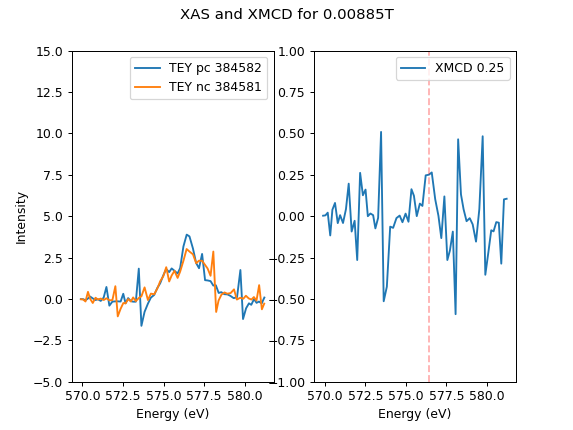

<IPython.core.display.Javascript object>


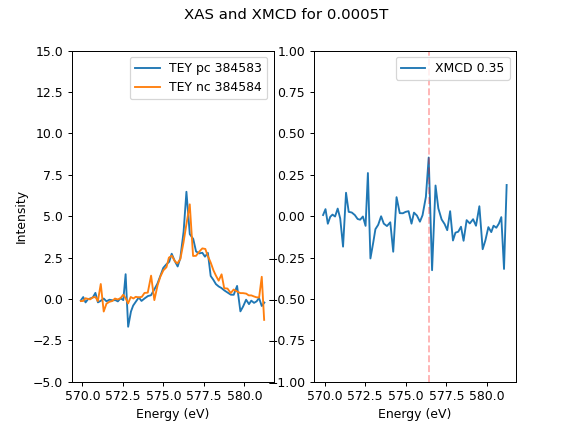

<IPython.core.display.Javascript object>


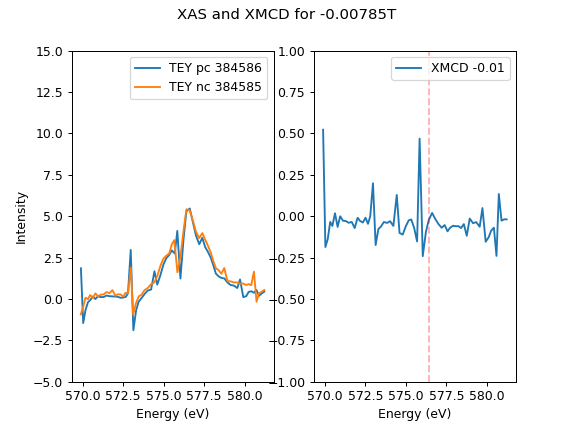

<IPython.core.display.Javascript object>


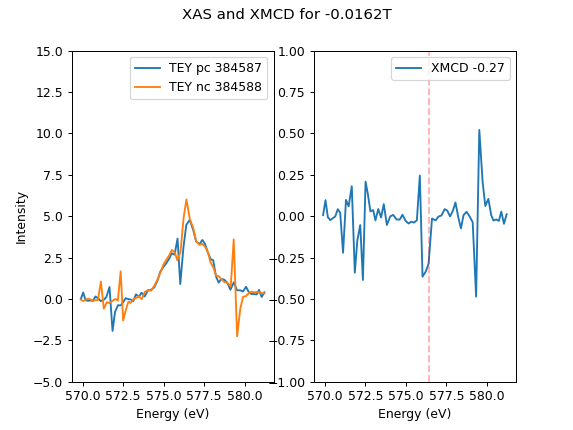

<IPython.core.display.Javascript object>


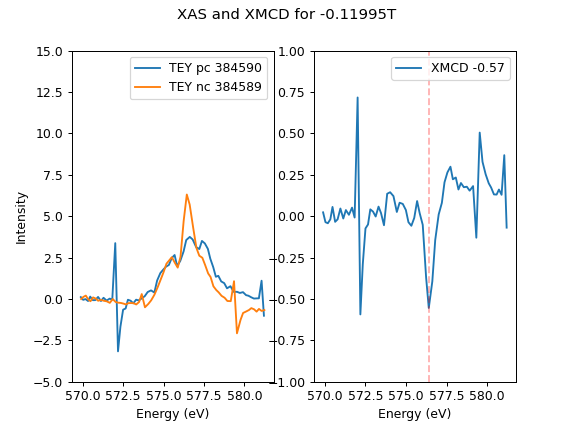

<IPython.core.display.Javascript object>


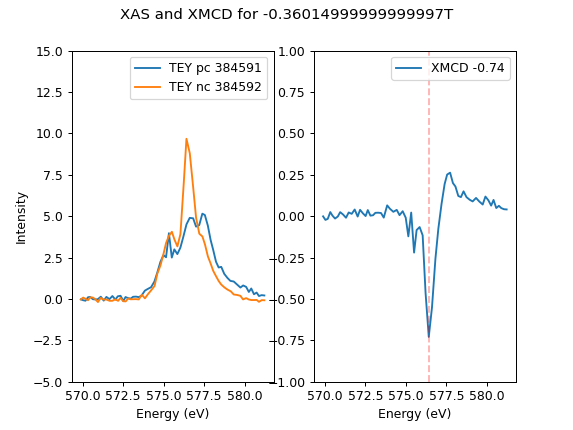

<IPython.core.display.Javascript object>


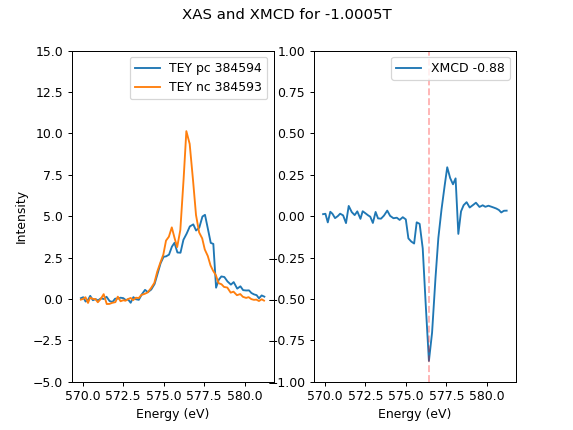

<IPython.core.display.Javascript object>


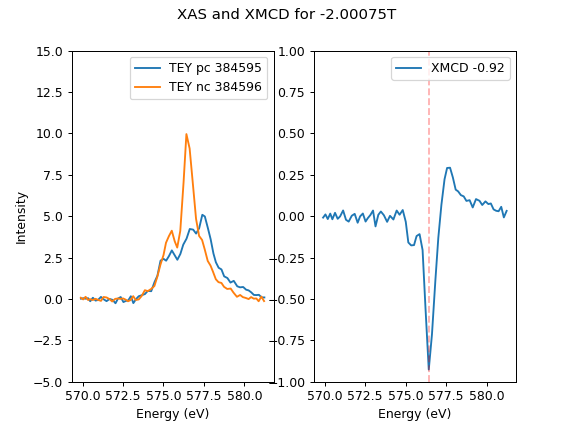

<IPython.core.display.Javascript object>


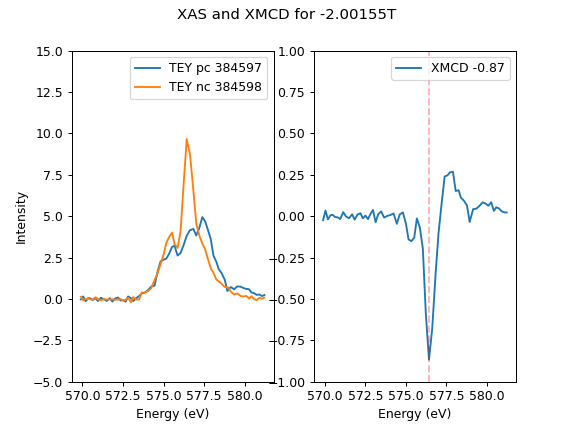

<IPython.core.display.Javascript object>


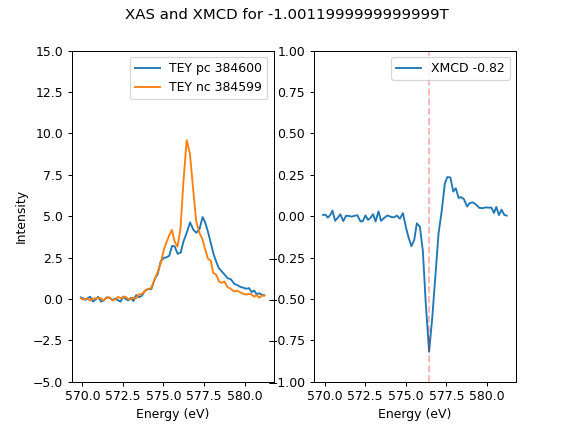

<IPython.core.display.Javascript object>


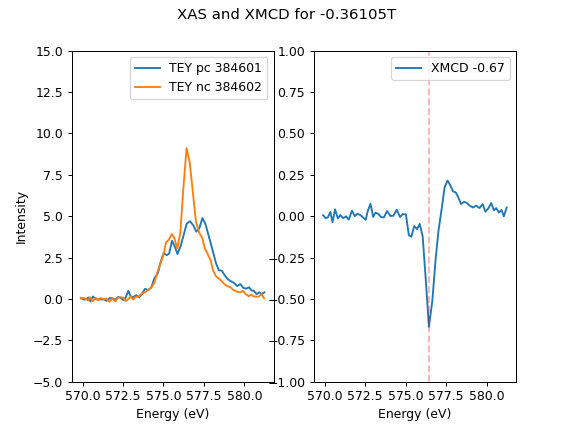

<IPython.core.display.Javascript object>


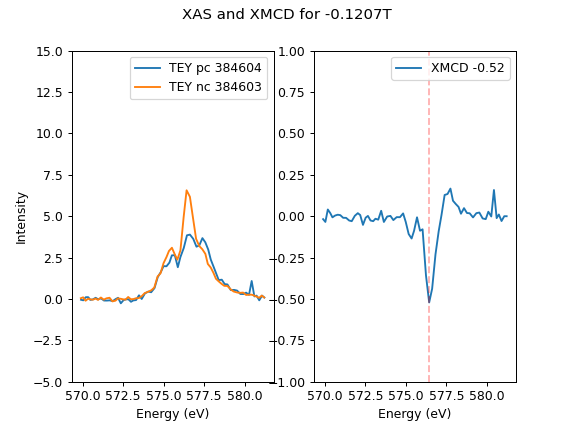

<IPython.core.display.Javascript object>


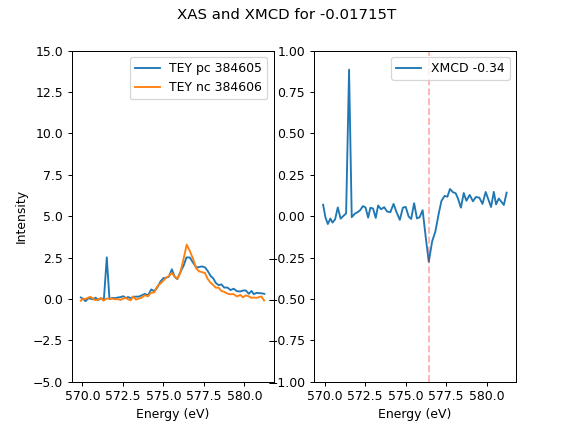

<IPython.core.display.Javascript object>


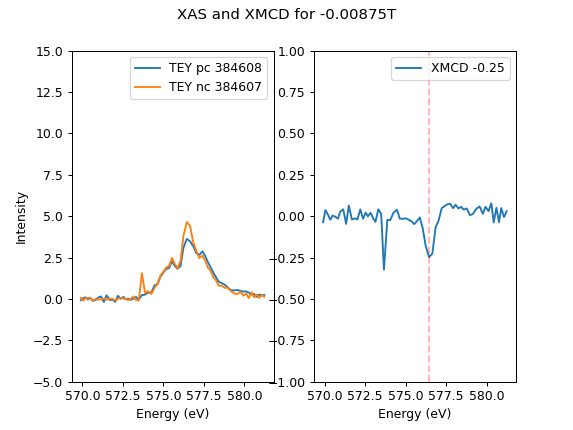

<IPython.core.display.Javascript object>


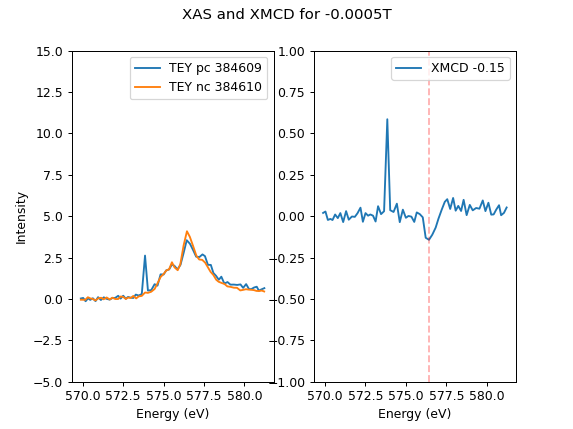

<IPython.core.display.Javascript object>


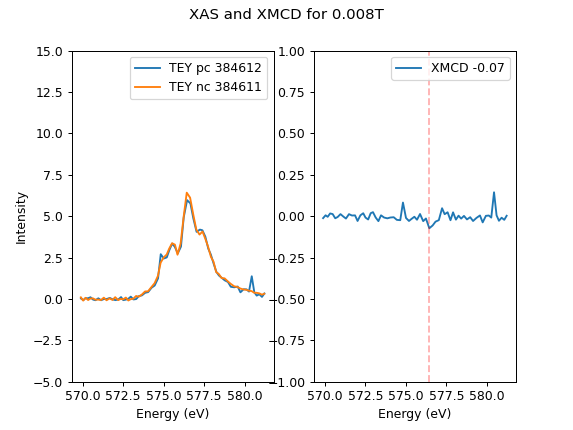

<IPython.core.display.Javascript object>


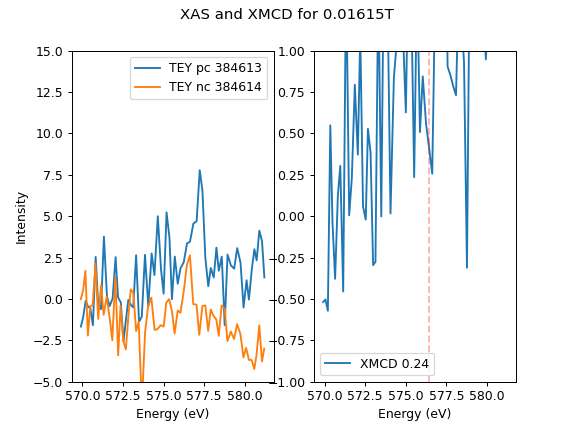

<IPython.core.display.Javascript object>


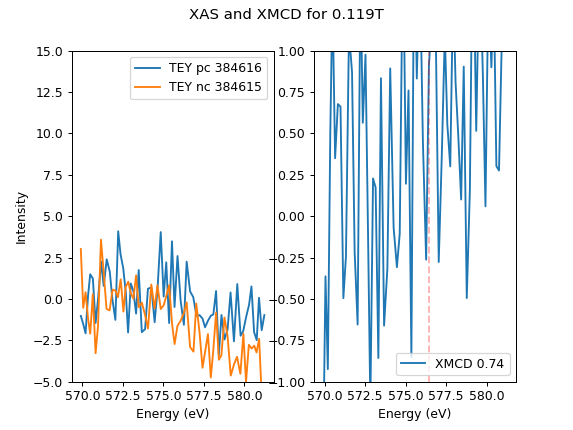

<IPython.core.display.Javascript object>


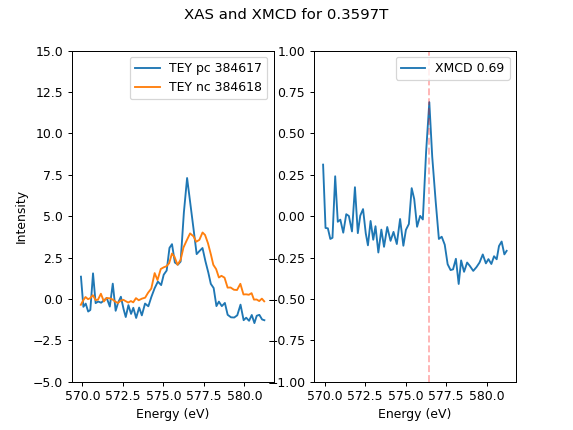

<IPython.core.display.Javascript object>


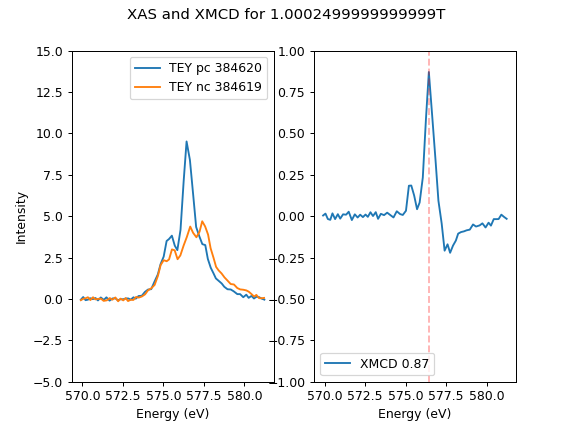

<IPython.core.display.Javascript object>


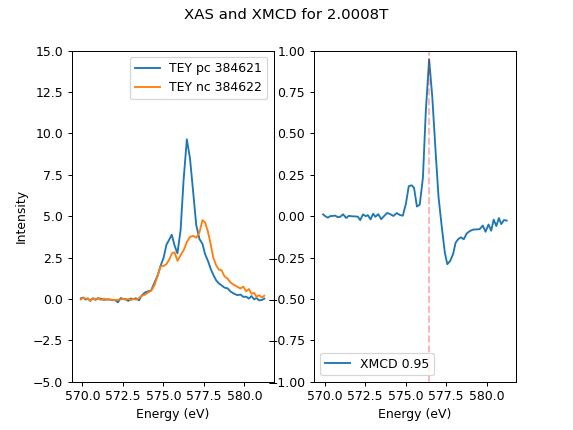

In [66]:
hysteresis_loop(384571,384622,plot=True, ylims=[15,-5])

Numbers mode


<IPython.core.display.Javascript object>


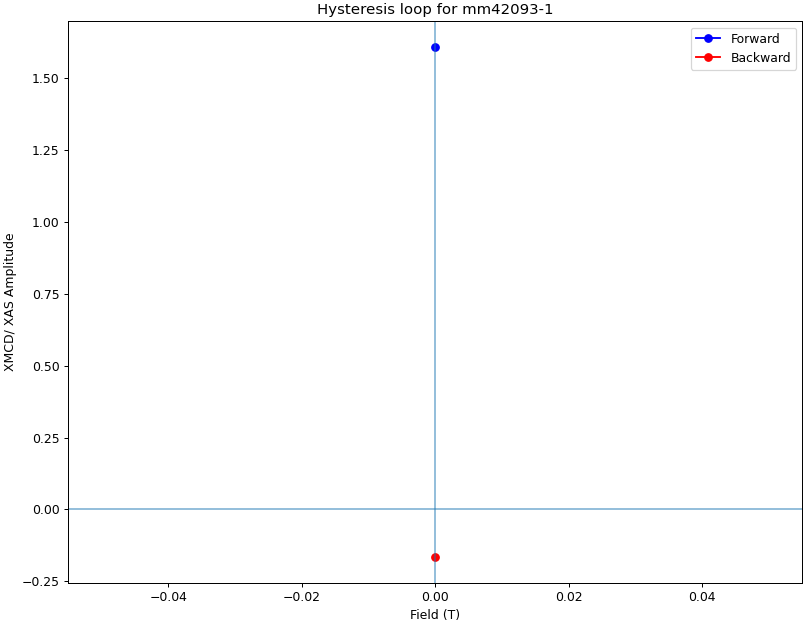

<IPython.core.display.Javascript object>


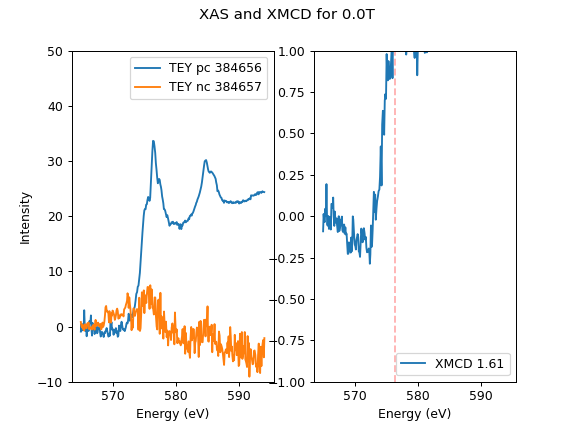

<IPython.core.display.Javascript object>


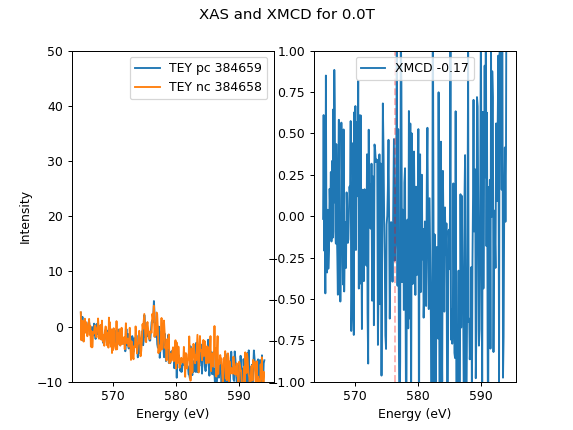

In [84]:
hysteresis_loop(384656,384659,plot=True, ylims=[50,-10])

Numbers mode


<IPython.core.display.Javascript object>


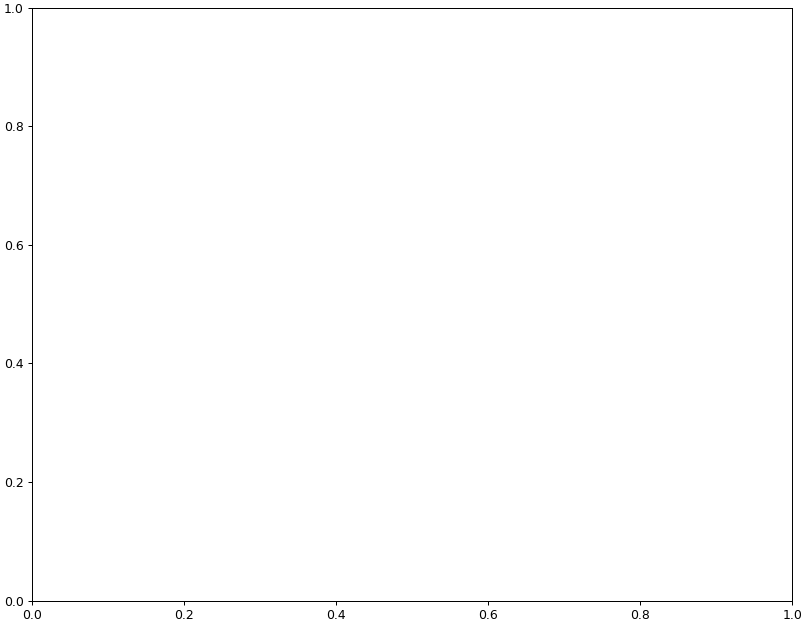

ValueError: No file to pair with /dls/i06-1/data/2026/mm42093-1/i06-1-384627.nxs

In [109]:
hysteresis_loop(384627,384628, plot=True, ylims=[21,-10])

In [104]:
hysteresis_loop(384733,384734, plot=True, ylims=[21,-10])

Numbers mode


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [110]:
hysteresis_loop(384735,384786, plot=True, ylims=[21,-10])

Numbers mode


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (18 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Numbers mode


<IPython.core.display.Javascript object>


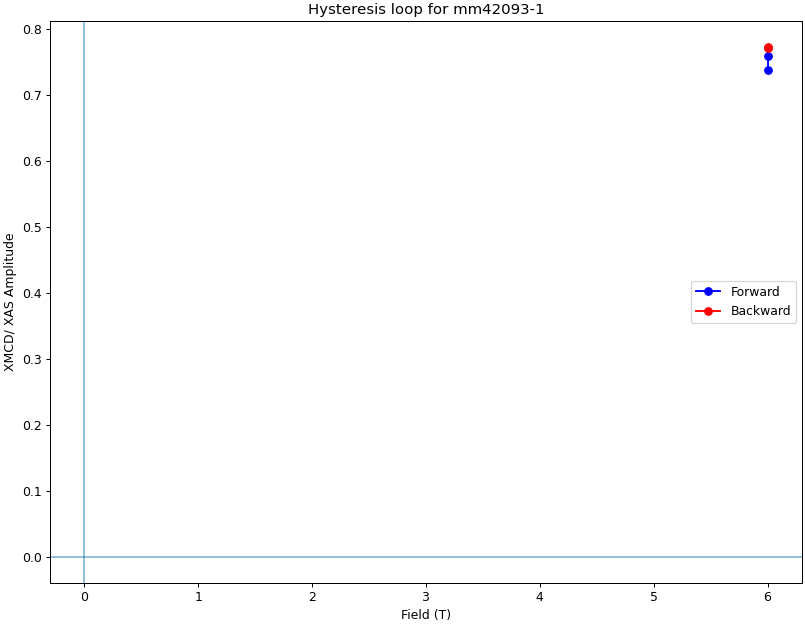

<IPython.core.display.Javascript object>


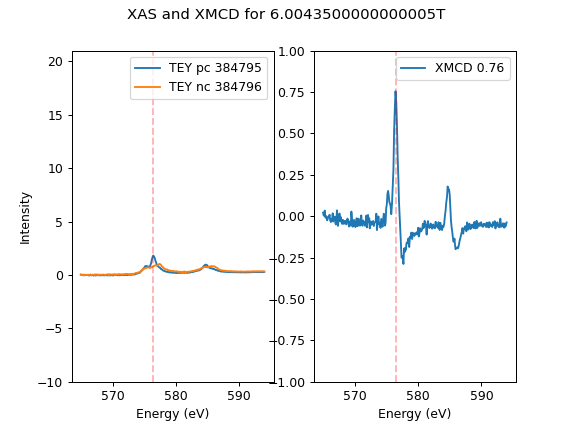

<IPython.core.display.Javascript object>


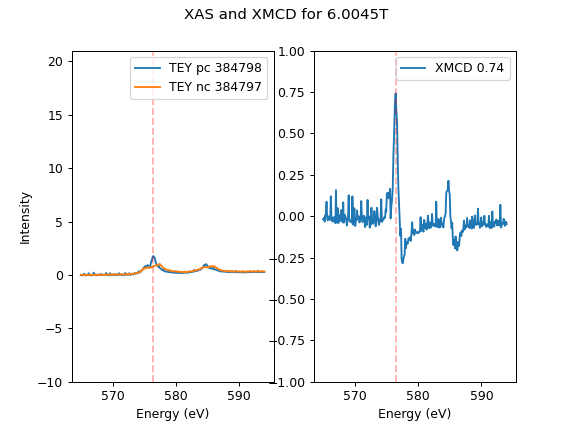

<IPython.core.display.Javascript object>


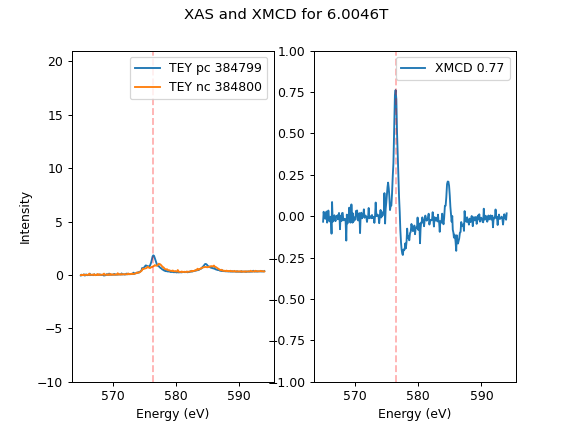

<IPython.core.display.Javascript object>


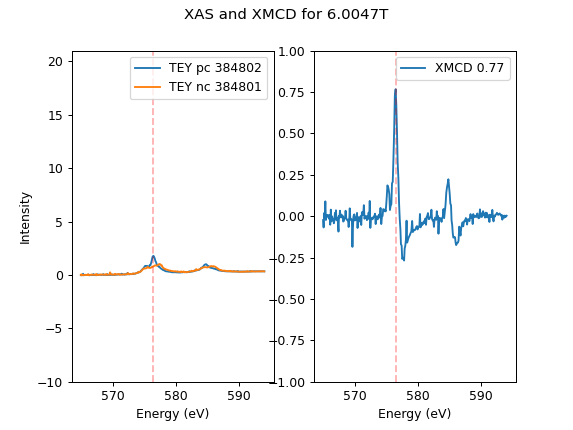

In [112]:
hysteresis_loop(384795,384802, plot=True, ylims=[21,-10])

Numbers mode


<IPython.core.display.Javascript object>


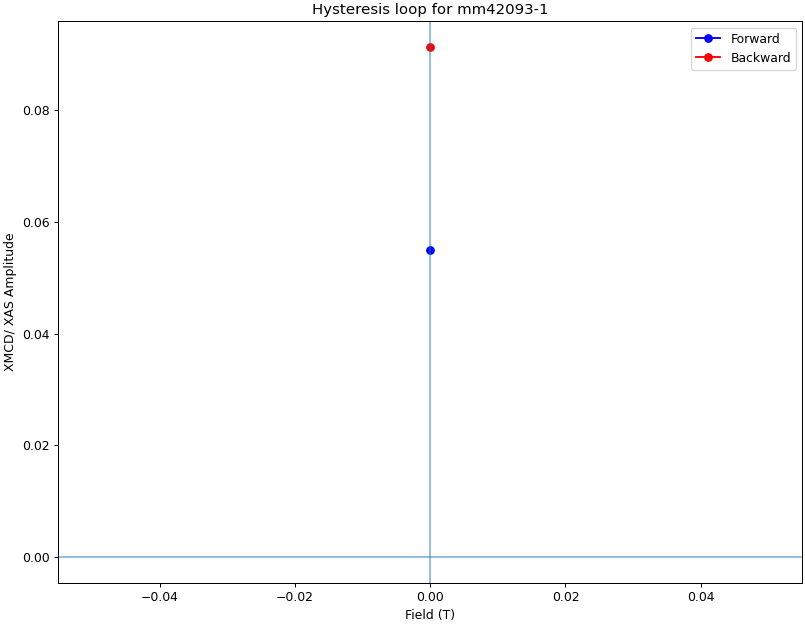

<IPython.core.display.Javascript object>


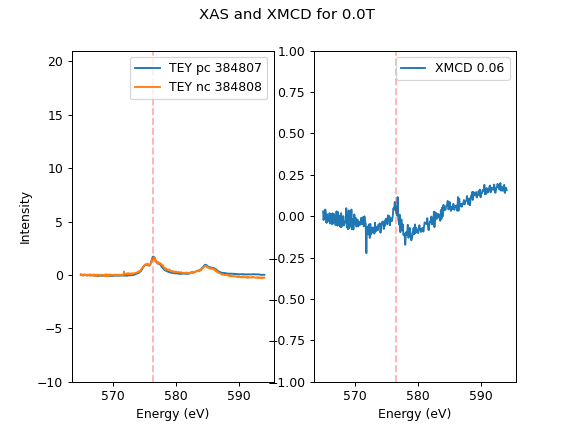

<IPython.core.display.Javascript object>


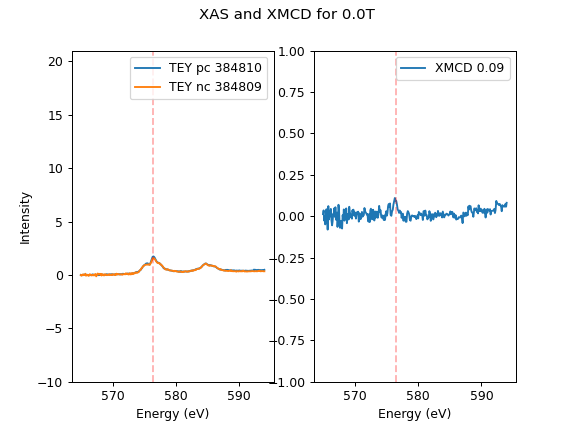

In [113]:
hysteresis_loop(384807,384810, plot=True, ylims=[21,-10])

Numbers mode


<IPython.core.display.Javascript object>


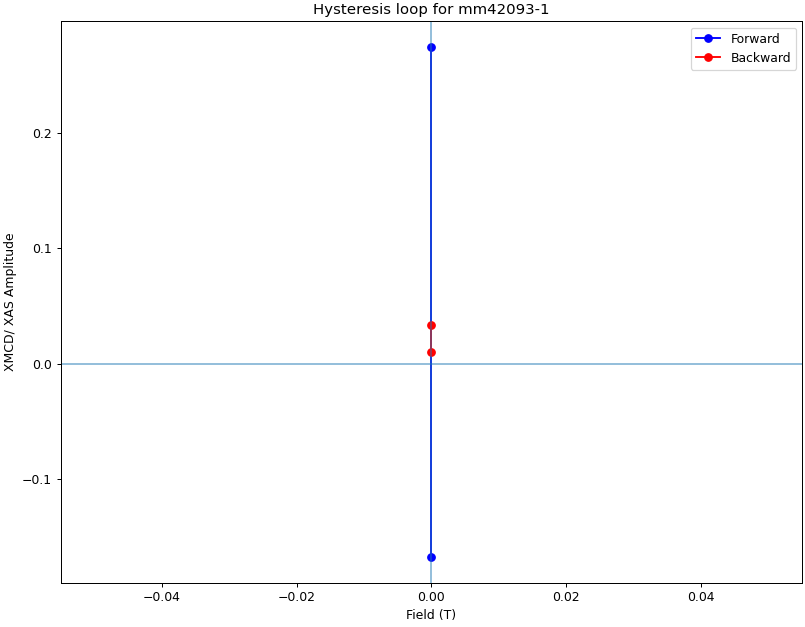

<IPython.core.display.Javascript object>


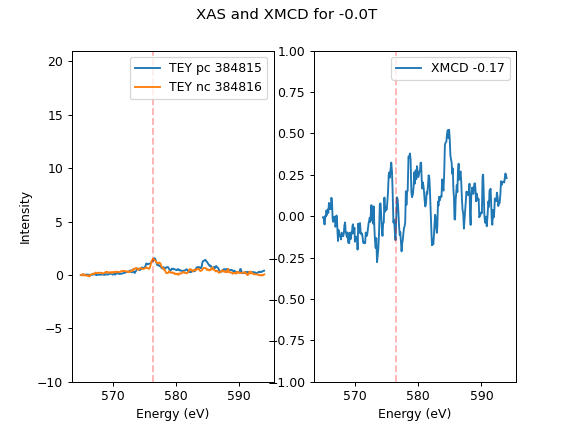

<IPython.core.display.Javascript object>


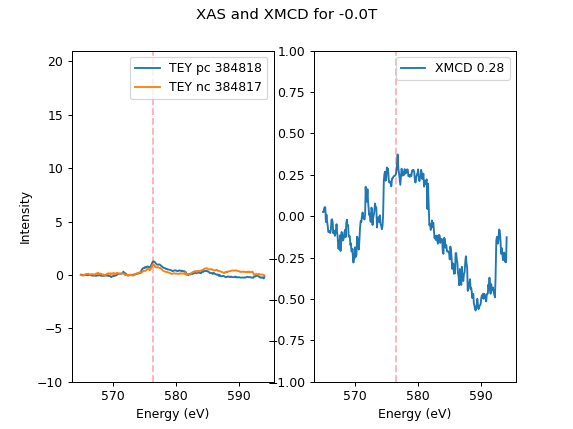

<IPython.core.display.Javascript object>


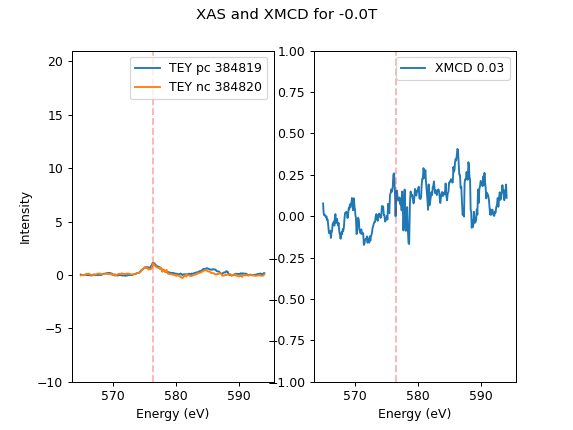

<IPython.core.display.Javascript object>


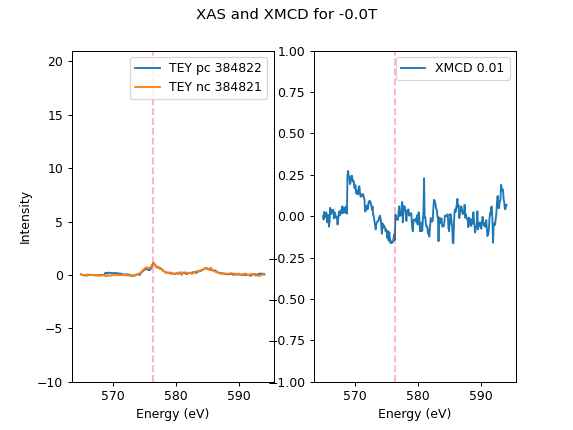

In [115]:
hysteresis_loop(384815,384822, plot=True, ylims=[21,-10])

Numbers mode


<IPython.core.display.Javascript object>


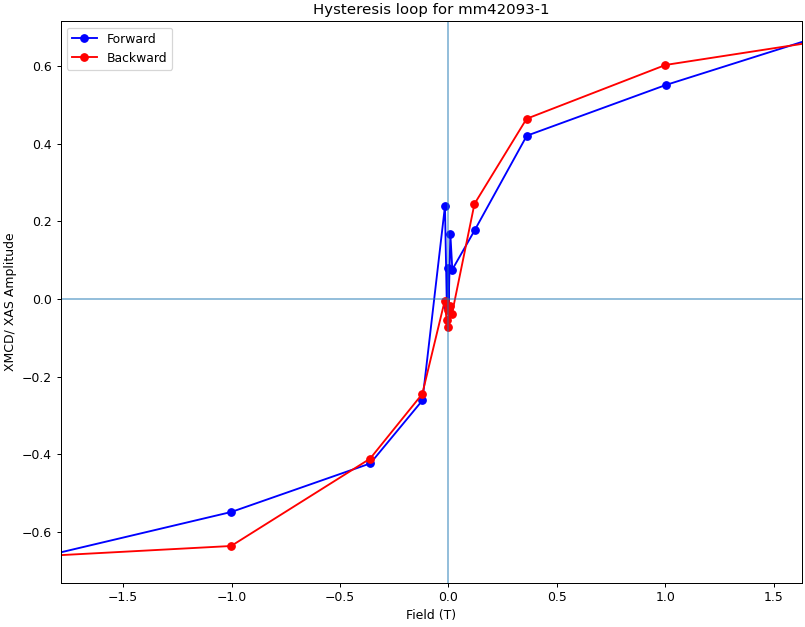

<IPython.core.display.Javascript object>


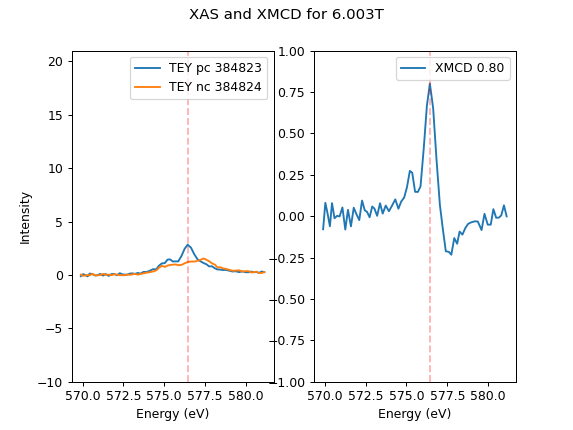

<IPython.core.display.Javascript object>


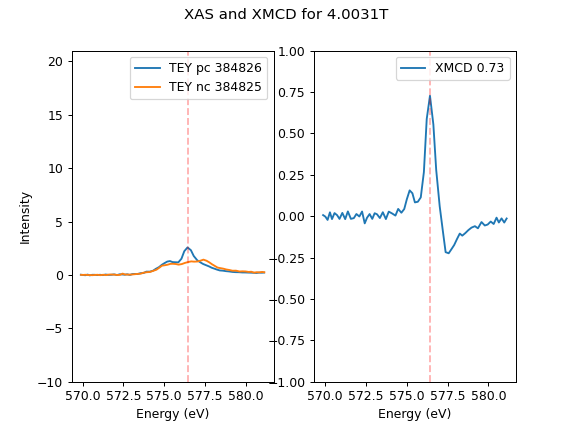

<IPython.core.display.Javascript object>


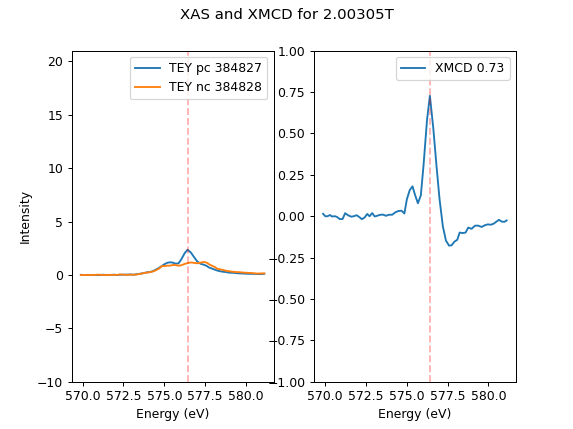

<IPython.core.display.Javascript object>


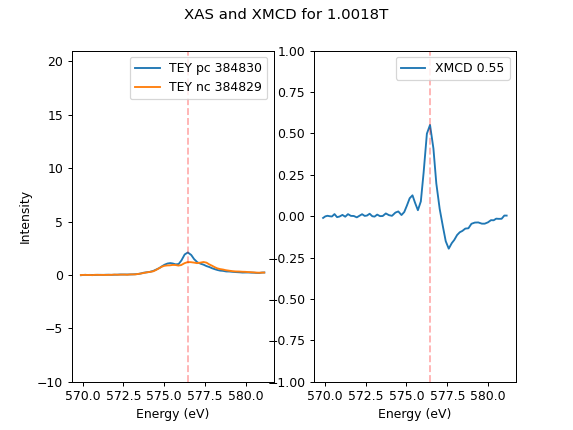

<IPython.core.display.Javascript object>


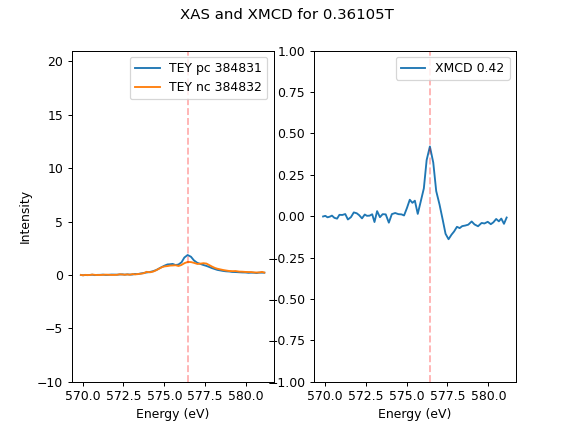

<IPython.core.display.Javascript object>


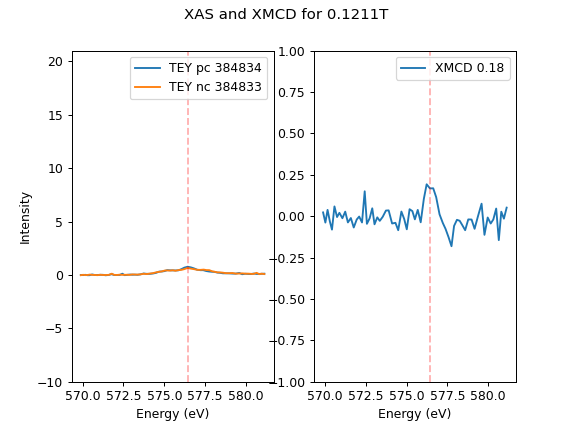

<IPython.core.display.Javascript object>


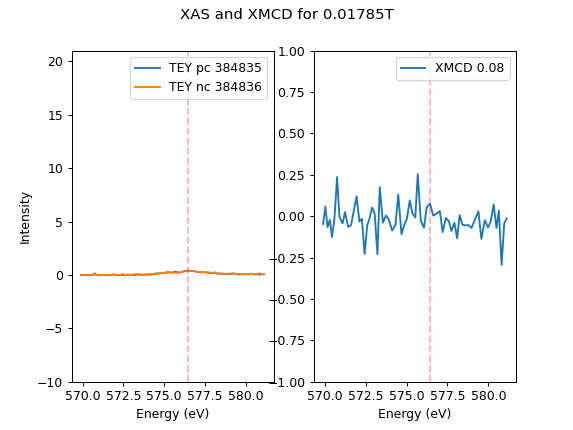

<IPython.core.display.Javascript object>


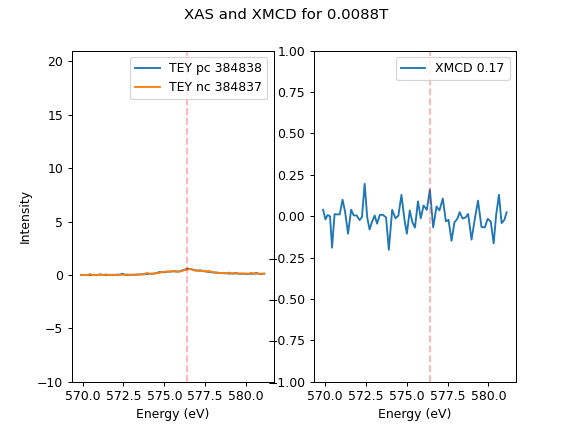

<IPython.core.display.Javascript object>


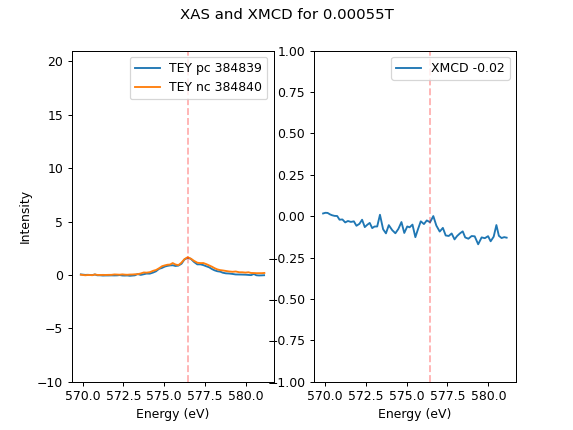

<IPython.core.display.Javascript object>


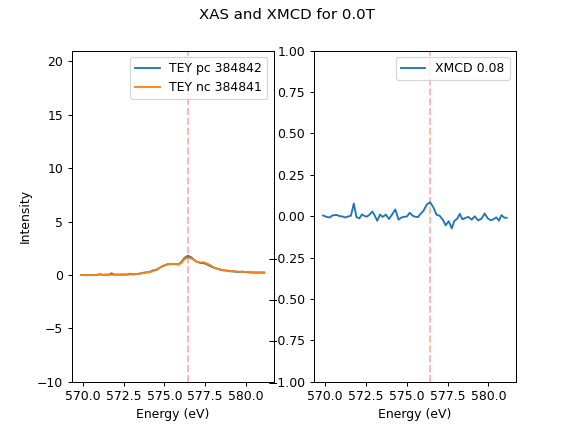

<IPython.core.display.Javascript object>


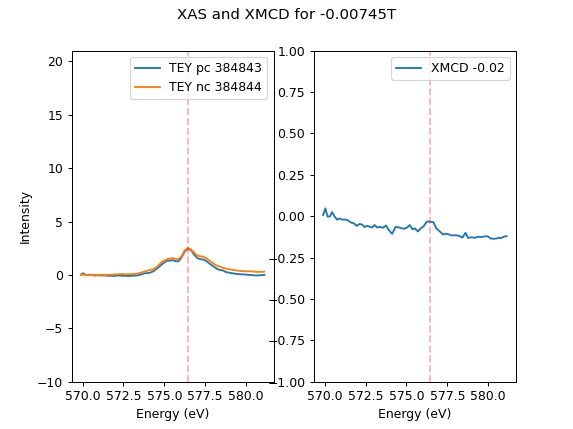

<IPython.core.display.Javascript object>


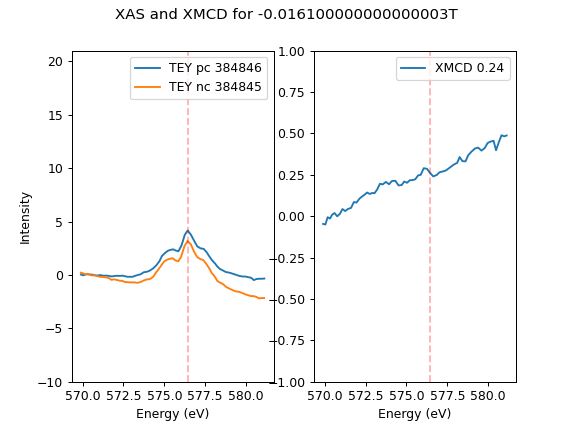

<IPython.core.display.Javascript object>


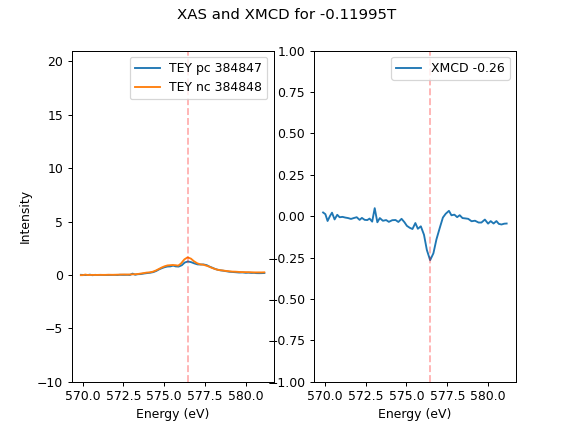

<IPython.core.display.Javascript object>


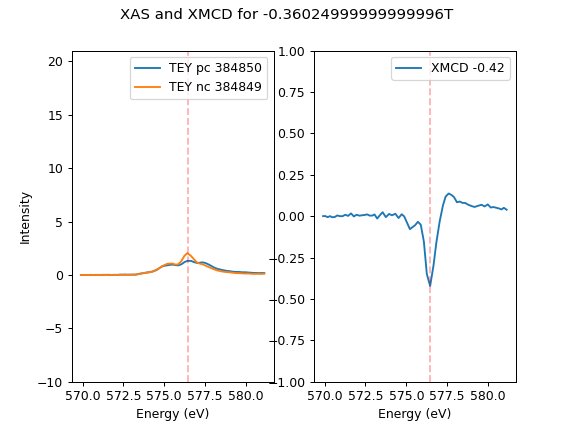

<IPython.core.display.Javascript object>


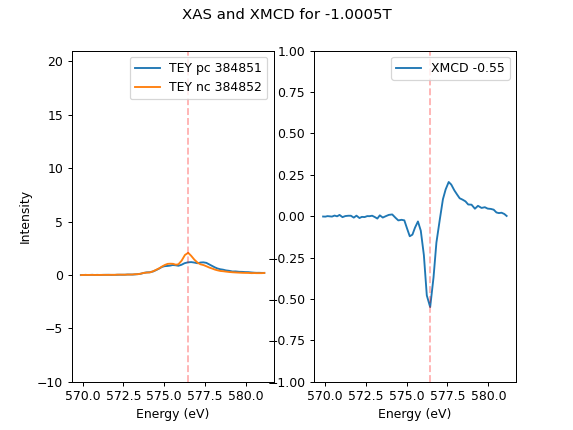

<IPython.core.display.Javascript object>


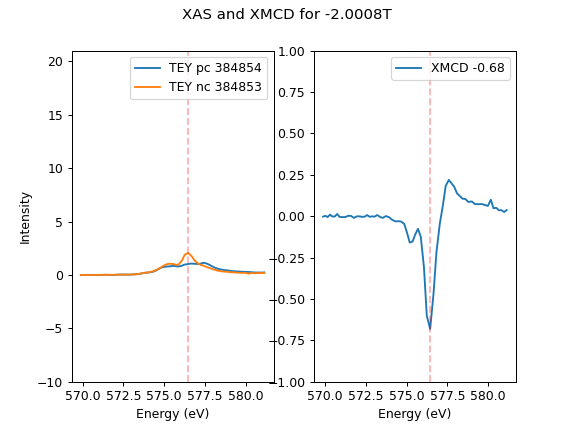

<IPython.core.display.Javascript object>


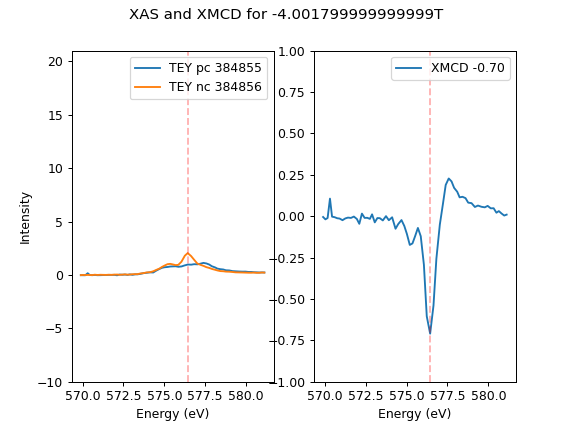

<IPython.core.display.Javascript object>


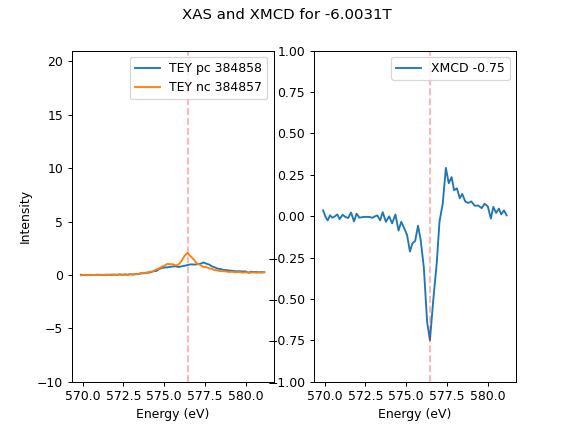

<IPython.core.display.Javascript object>


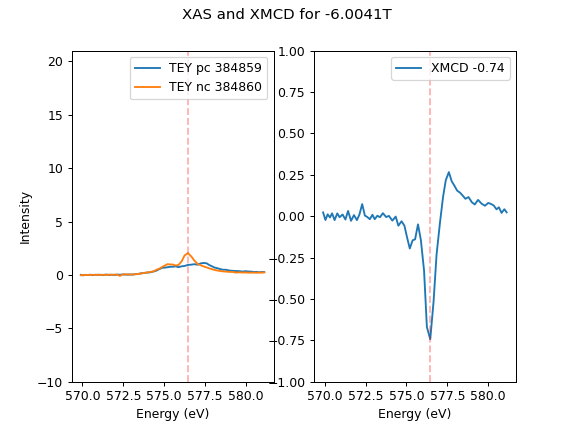

<IPython.core.display.Javascript object>


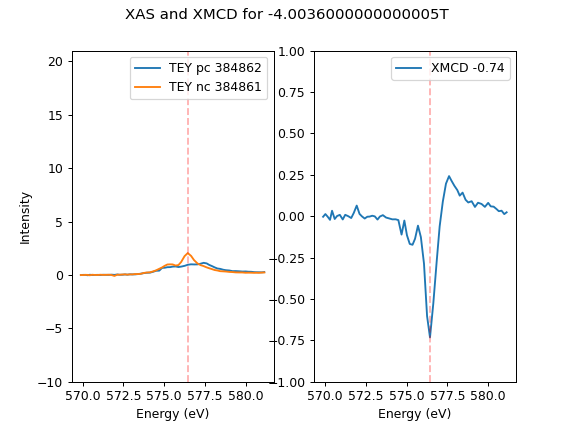

<IPython.core.display.Javascript object>


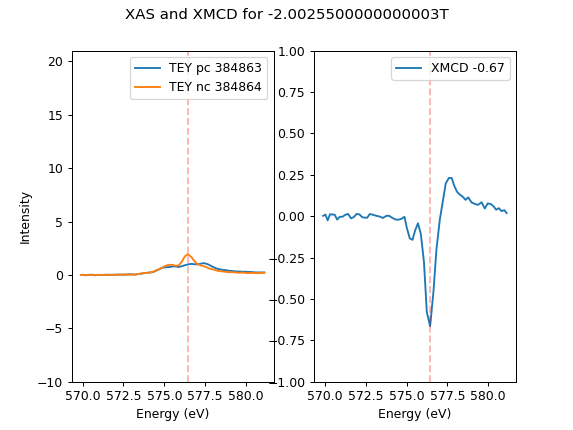

<IPython.core.display.Javascript object>


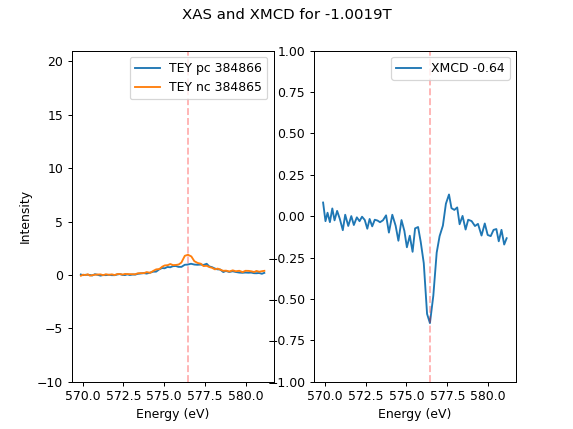

<IPython.core.display.Javascript object>


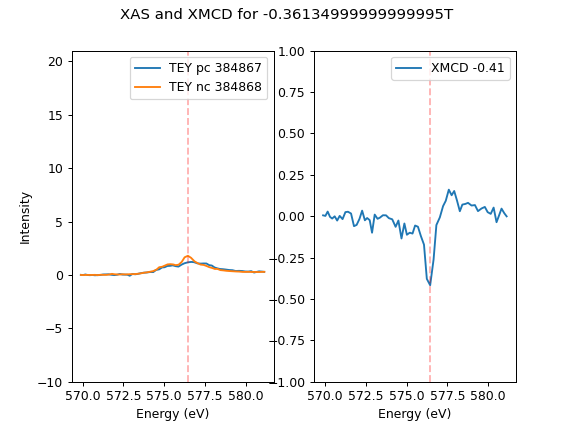

<IPython.core.display.Javascript object>


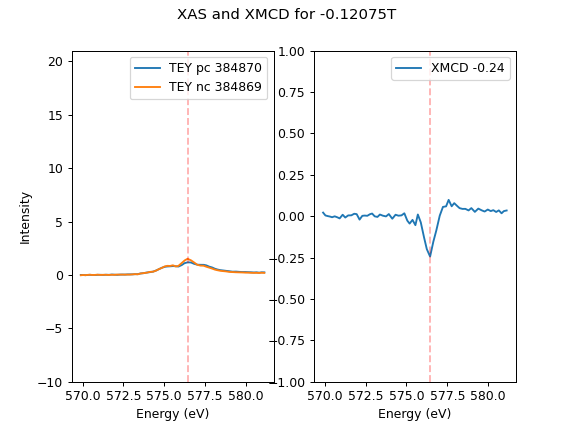

<IPython.core.display.Javascript object>


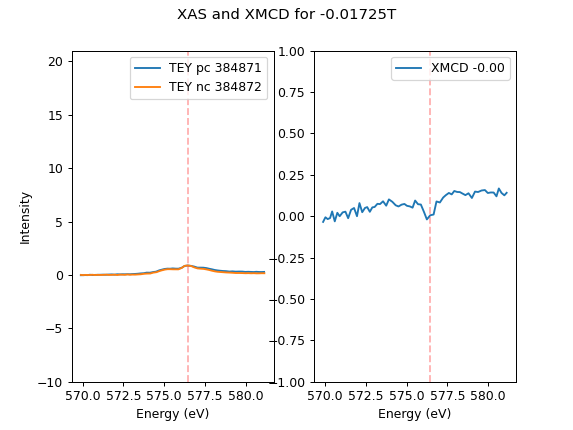

<IPython.core.display.Javascript object>


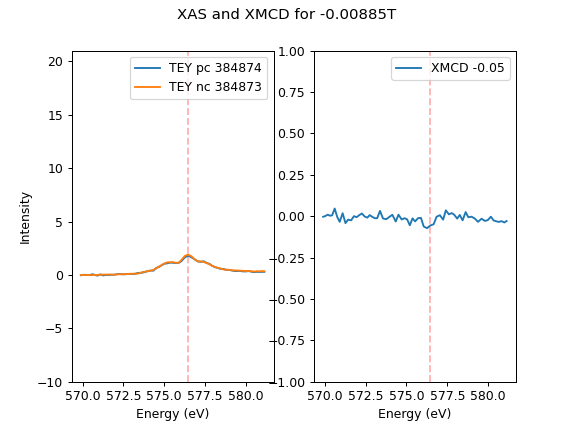

<IPython.core.display.Javascript object>


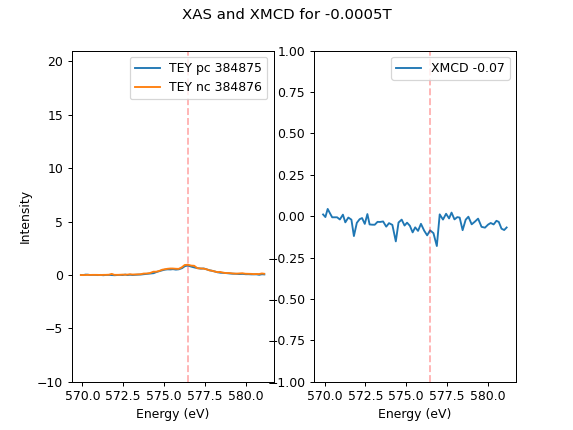

<IPython.core.display.Javascript object>


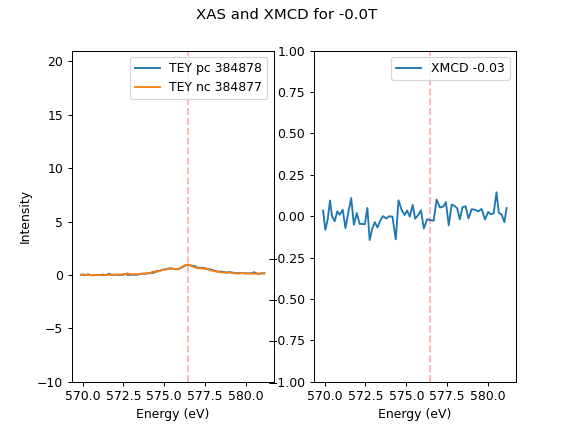

<IPython.core.display.Javascript object>


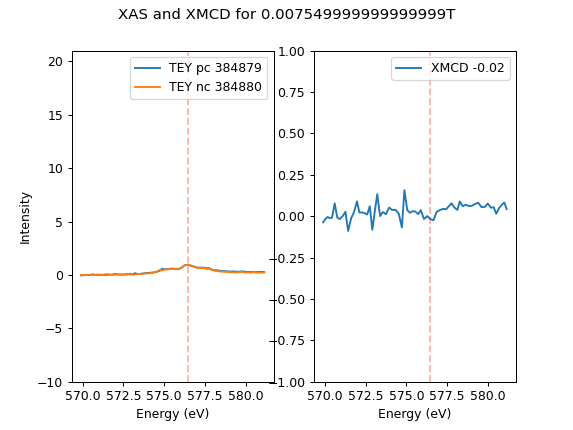

<IPython.core.display.Javascript object>


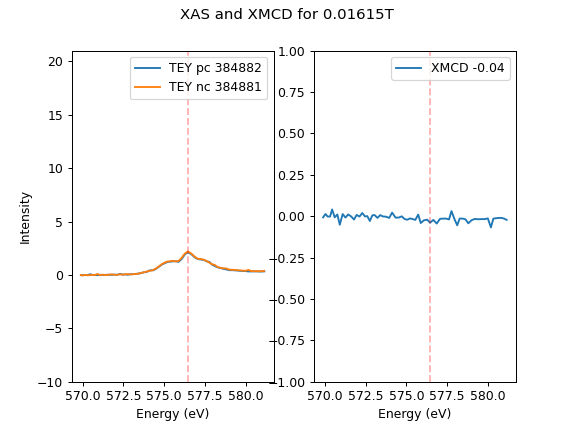

<IPython.core.display.Javascript object>


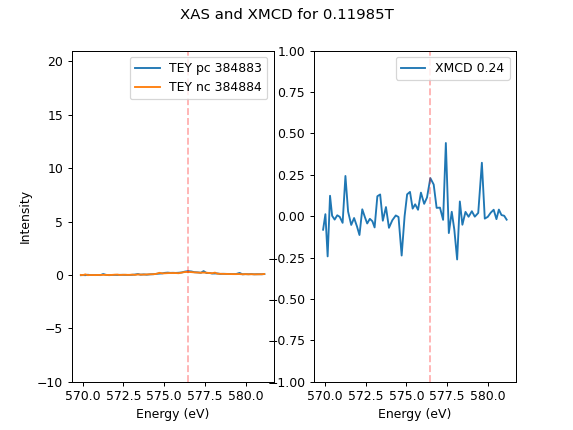

<IPython.core.display.Javascript object>


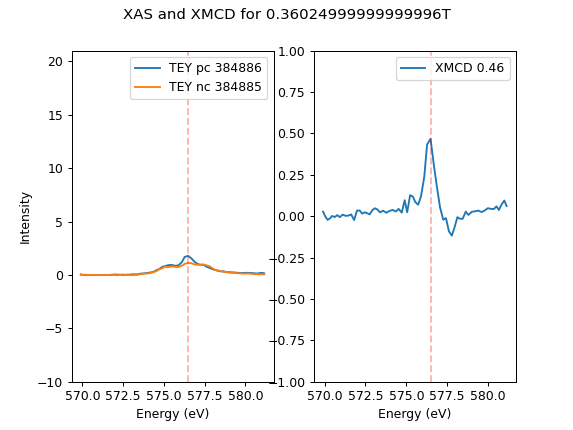

<IPython.core.display.Javascript object>


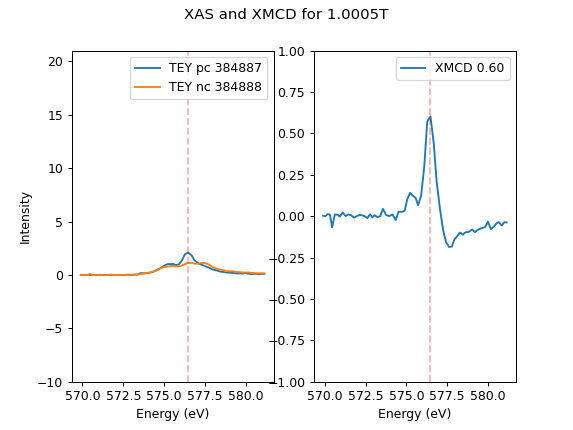

<IPython.core.display.Javascript object>


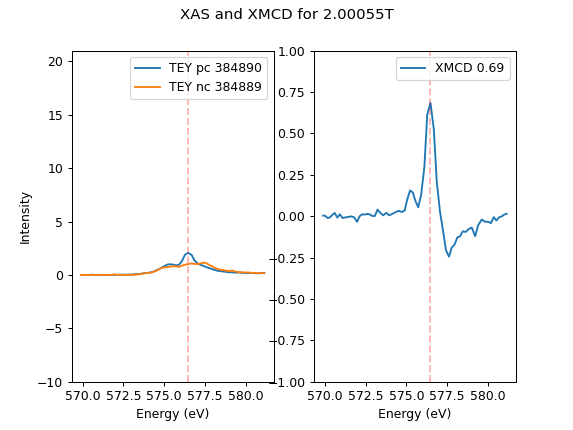

<IPython.core.display.Javascript object>


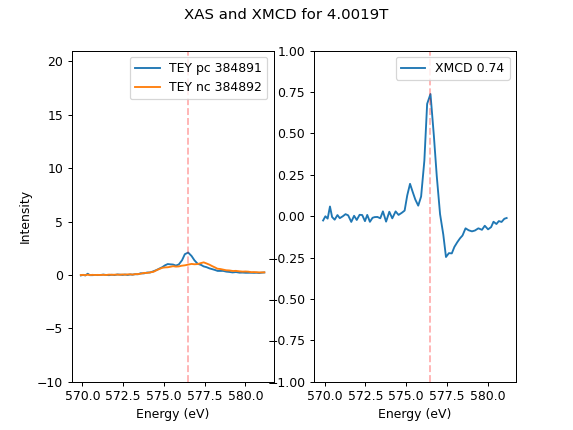

<IPython.core.display.Javascript object>


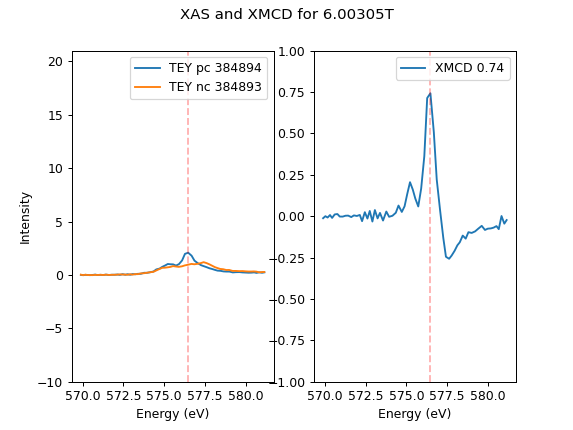

In [119]:
hysteresis_loop(384823,384894, plot=True, ylims=[21,-10])